<a href="https://colab.research.google.com/github/Prasadn1234/DataScience/blob/main/Week_7_Assignment_Supply_Chain_Project_07072026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Contract Intelligence Multi-Agent System
## Assignment Notebook - 8-Week Capstone Project

**Course**: Agentic AI Bootcamp - Staff-Level System Design

---

## Welcome to Your Capstone Assignment!

This notebook is your guided journey to building a **production-grade multi-agent contract intelligence system**. Unlike the master solution, YOU will implement the core functionality.

### How This Assignment Works

1. **Scaffolding Provided**: Class structures, function signatures, and imports are given
2. **TODO Markers**: Look for `# TODO:` comments - these are YOUR tasks
3. **Hints**: Each section has hints to guide you (but not give away the answer)
4. **Validation Cells**: Run these to check if your implementation is correct
5. **Expected Output**: Sample outputs show what success looks like

### Difficulty Progression

| Week | Difficulty | Focus |
|------|-----------|-------|
| 1 | Easy | Environment setup (mostly provided) |
| 2 | Easy-Medium | Document processing methods |
| 3 | Medium | Vector store search functions |
| 4 | Medium-Hard | Implement agents from scratch |
| 5 | Hard | Multi-agent orchestration |
| 6 | Medium | Build knowledge graph |
| 7 | Medium | Add observability metrics |
| 8 | Hard | Integrate everything |

### Grading Rubric

- **Week 1-2**: 15% (Foundation)
- **Week 3-4**: 30% (Core Components)  
- **Week 5-6**: 30% (Advanced Features)
- **Week 7-8**: 25% (Production Polish)

Let's begin!

---

# WEEK 1: Environment & Foundations

**Difficulty: Easy** - Most code is provided. Focus on understanding.

---

## Learning Objectives

By the end of Week 1, you will:
- [ ] Set up all required packages
- [ ] Configure API keys securely
- [ ] Initialize Langfuse for observability
- [ ] Create traced wrapper functions
- [ ] Explore the contract data structure

---

In [1]:
from pathlib import Path
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Define the directory path using quotes
DATA_DIR = Path('/content/drive/MyDrive/dataset')

# Check if the directory exists
print(f"Exists after mount: {DATA_DIR.exists()}")


Mounted at /content/drive
Exists after mount: True


## 1.1 Package Installation

This section is **provided** - just run the cell to install packages.

In [2]:
# ============================================================================
# WEEK 1.1: PACKAGE INSTALLATION (PROVIDED)
# ============================================================================
# Pinned versions for reproducibility. Every package is verified after install.

import subprocess, sys

_packages = ["openai==1.59.6", "langfuse==2.57.1", "langchain==0.3.14", "langchain-openai==0.2.14", "langchain-community==0.3.14", "langchain-core==0.3.29", "chromadb", "networkx", "pyvis", "python-docx", "openpyxl", "plotly", "seaborn", "pydantic>=2.0", "tenacity", "rich", "gradio", "python-dotenv", "numpy", "pandas", "matplotlib"]

print("Installing packages (this may take 1-2 minutes)...")
result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q"] + _packages,
    capture_output=True, text=True
)

if result.returncode != 0:
    for line in result.stderr.split("\n"):
        if line.strip() and "dependency resolver" not in line.lower() and "notice" not in line.lower():
            print(line)

# ---------- Verify EVERY import ----------
_verify = [
    ("openai", "openai"),
    ("langfuse", "langfuse"),
    ("langchain", "langchain"),
    ("langchain_openai", "langchain_openai"),
    ("chromadb", "chromadb"),
    ("networkx", "networkx"),
    ("pyvis", "pyvis.network"),
    ("docx", "docx"),
    ("openpyxl", "openpyxl"),
    ("plotly", "plotly"),
    ("seaborn", "seaborn"),
    ("pydantic", "pydantic"),
    ("tenacity", "tenacity"),
    ("rich", "rich"),
    ("gradio", "gradio"),
    ("dotenv", "dotenv"),
    ("fastapi", "fastapi"),
    ("uvicorn", "uvicorn"),
]

_failed = []
for name, imp in _verify:
    try:
        __import__(imp)
    except ImportError:
        _failed.append(name)

if _failed:
    msg = f"FATAL: These packages failed to import: {', '.join(_failed)}\n"
    msg += "Try: Runtime > Restart runtime, then re-run this cell."
    raise ImportError(msg)

print("=" * 60)
print(f"All {len(_verify)} packages installed and verified!")
print("=" * 60)

Installing packages (this may take 1-2 minutes)...
All 18 packages installed and verified!


## 1.2 Environment Configuration

This section is **provided** - handles environment detection and imports.

In [3]:
# ============================================================================
# WEEK 1.2: ENVIRONMENT DETECTION (PROVIDED)
# ============================================================================

import os
import sys
import json
import pandas as pd
import numpy as np
from pathlib import Path
from datetime import datetime
from typing import List, Dict, Optional, Any, Tuple
from dataclasses import dataclass, field
from enum import Enum
import warnings
warnings.filterwarnings('ignore')

# Environment detection
IN_COLAB = 'google.colab' in sys.modules

print(f"Runtime Environment: {'Google Colab' if IN_COLAB else 'Local/Other'}")
print(f"Python Version: {sys.version.split()[0]}")

Runtime Environment: Google Colab
Python Version: 3.12.13


In [4]:
# ============================================================================
# API KEY CONFIGURATION (PROVIDED)
# ============================================================================

import subprocess

DATASET_REPO = "https://github.com/AI-Project-Lab/IK-pwc-agenticai-datasets.git"
DATASET_PROJECT = "contract_intelligence"

if IN_COLAB:
    print("Configuring for Google Colab environment...")

    # --- API Key Configuration ---
    try:
        from google.colab import userdata
        os.environ['OPENAI_API_KEY'] = userdata.get('OPENAI_API_KEY')
        os.environ['LANGFUSE_SECRET_KEY'] = userdata.get('LANGFUSE_SECRET_KEY')
        os.environ['LANGFUSE_PUBLIC_KEY'] = userdata.get('LANGFUSE_PUBLIC_KEY')
        _host = userdata.get('LANGFUSE_HOST') or ''
        os.environ['LANGFUSE_HOST'] = _host if _host.startswith('http') else 'https://jp.cloud.langfuse.com'
        print("API keys loaded from Colab Secrets")
    except Exception as e:
        print(f"Colab Secrets not available: {e}")
        import getpass
        os.environ['OPENAI_API_KEY'] = getpass.getpass('Enter OpenAI API Key: ')
        os.environ['LANGFUSE_SECRET_KEY'] = getpass.getpass('Enter Langfuse Secret Key: ')
        os.environ['LANGFUSE_PUBLIC_KEY'] = getpass.getpass('Enter Langfuse Public Key: ')
        os.environ['LANGFUSE_HOST'] = 'https://jp.cloud.langfuse.com'

    # --- Dataset Ingestion from GitHub ---
    dataset_path = "/content/drive/MyDrive/dataset"
    if not os.path.exists(f"{dataset_path}/{DATASET_PROJECT}"):
        print(f"\nCloning dataset from {DATASET_REPO}...")
        subprocess.run(["git", "clone", "--depth", "1", DATASET_REPO, dataset_path],
                       check=True, capture_output=True)
        print("Dataset cloned successfully!")
    else:
        print("\nDataset already available.")
    DATA_DIR_BASE = f"{dataset_path}/{DATASET_PROJECT}"
else:
    print("Configuring for local environment...")
    from dotenv import load_dotenv
    load_dotenv()

    # --- Dataset Ingestion from GitHub ---
    datasets_parent = Path('.').resolve().parent.parent / 'dataset'
    if not (datasets_parent / DATASET_PROJECT).exists():
        print(f"\nCloning dataset from {DATASET_REPO}...")
        subprocess.run(["git", "clone", "--depth", "1", DATASET_REPO, str(datasets_parent)],
                       check=True, capture_output=True)
        print("Dataset cloned successfully!")
    else:
        print("\nDataset already available locally.")
    DATA_DIR_BASE = str(datasets_parent / DATASET_PROJECT)

# Validate API keys
required_keys = ['OPENAI_API_KEY', 'LANGFUSE_SECRET_KEY', 'LANGFUSE_PUBLIC_KEY']
missing_keys = [key for key in required_keys if not os.environ.get(key)]
if missing_keys:
    raise EnvironmentError(f"Missing required API keys: {missing_keys}")

PROJECT_NAME = "contract-intelligence-system"
DATA_DIR = Path(DATA_DIR_BASE)
print(f"\nAll API keys validated successfully")
print(f"Data directory: {DATA_DIR}")
print(f"Directory exists: {DATA_DIR.exists()}")
if DATA_DIR.exists():
    file_count = sum(1 for _ in DATA_DIR.rglob('*') if _.is_file())
    print(f"Total files found: {file_count}")

Configuring for Google Colab environment...
API keys loaded from Colab Secrets

Dataset already available.

All API keys validated successfully
Data directory: /content/drive/MyDrive/dataset/contract_intelligence
Directory exists: True
Total files found: 36


## 1.3 Langfuse Initialization

**YOUR FIRST TODO!** Initialize the Langfuse client.

### Hints:
- Import `Langfuse` from `langfuse`
- Import `observe` and `langfuse_context` from `langfuse.decorators`
- Use environment variables for credentials
- Call `auth_check()` to verify connection

In [5]:
# ============================================================================
# WEEK 1.3: LANGFUSE INITIALIZATION
# ============================================================================
import os
from datetime import datetime
from langfuse import Langfuse
from langfuse.decorators import observe, langfuse_context
from openai import OpenAI
# Initialize the Langfuse client
langfuse = Langfuse(
    secret_key=os.environ.get("LANGFUSE_SECRET_KEY"),
    public_key=os.environ.get("LANGFUSE_PUBLIC_KEY"),
    host=os.environ.get("LANGFUSE_HOST", "https://jp.cloud.langfuse.com"),
)
# Verify connection
try:
    langfuse.auth_check()
    print("Langfuse connection verified!")
except Exception as e:
    print(f"Langfuse connection failed: {e}")
# Create a unique session ID
SESSION_ID = f"contract-intel-{datetime.now().strftime('%Y%m%d-%H%M%S')}"
print(f"Session ID: {SESSION_ID}")

Langfuse connection verified!
Session ID: contract-intel-20260708-160614


## 1.4 Traced Wrapper Functions

**TODO:** Implement traced versions of OpenAI calls.

### Hints:
- Create a trace with `langfuse.trace()`
- Create a generation span with `trace.generation()`
- Use `openai_client.embeddings.create()` for embeddings
- End the generation with usage stats

In [6]:
# ============================================================================
# WEEK 1.4: TRACED EMBEDDING FUNCTION
# ============================================================================
from typing import List
# Initialize OpenAI client (PROVIDED)
openai_client = OpenAI()
def traced_embedding(text: str, trace_name: str = "embedding") -> List[float]:
    """
    Generate embedding with full Langfuse tracing.
    """
    # 1. Create trace
    trace = langfuse.trace(
        name=trace_name,
        session_id=SESSION_ID,
        metadata={
            "text_length": len(text),
            "project": "contract-intel",
        },
    )
    # 2. Create generation span
    generation = trace.generation(
        name="openai-embedding",
        model="text-embedding-3-small",
        input=text,
    )
    # 3. Make API call
    response = openai_client.embeddings.create(
        model="text-embedding-3-small",
        input=text,
    )
    embedding = response.data[0].embedding
    # 4. End generation with metadata
    generation.end(
        output={"dimensions": len(embedding)},
        usage={
            "input": response.usage.prompt_tokens,
            "total": response.usage.total_tokens,
        },
    )
    # 5. Return embedding
    return embedding
print("traced_embedding() function defined")

traced_embedding() function defined


In [7]:
# Quick test cell #
sample_text = "Master service agreement between Acme Corp and Beta LLC."
vector = traced_embedding(sample_text, trace_name="test-embedding")
print(f"Embedding dimensions: {len(vector)}")
print(f"First 5 values: {vector[:5]}")
print(f"Check trace in Langfuse dashboard for session: {SESSION_ID}")

Embedding dimensions: 1536
First 5 values: [-0.0203399658203125, 0.0223236083984375, 0.05340576171875, -0.006641387939453125, -0.01352691650390625]
Check trace in Langfuse dashboard for session: contract-intel-20260708-160614


In [8]:
# ============================================================================
# WEEK 1.4: TRACED COMPLETION FUNCTION
# ============================================================================
def traced_completion(prompt: str, trace_name: str = "completion") -> str:
    """
    Generate completion with full Langfuse tracing.
    """
    # 1. Create trace
    trace = langfuse.trace(
        name=trace_name,
        session_id=SESSION_ID,
        metadata={
            "prompt_length": len(prompt),
            "project": "contract-intel",
        },
    )
    # 2. Create generation span
    generation = trace.generation(
        name="openai-chat-completion",
        model="gpt-4.1-2025-04-14",
        input=[{"role": "user", "content": prompt}],
    )
    # 3. Make API call
    response = openai_client.chat.completions.create(
        model="gpt-4.1-2025-04-14",
        messages=[{"role": "user", "content": prompt}],
    )
    response_text = response.choices[0].message.content
    # 4. End generation with usage stats
    generation.end(
        output=response_text,
        usage={
            "input": response.usage.prompt_tokens,
            "output": response.usage.completion_tokens,
            "total": response.usage.total_tokens,
        },
    )
    return response_text
print("traced_completion() function defined")

traced_completion() function defined


In [9]:
# Quick test #
result = traced_completion(
    "Summarize the key risks in a vendor master service agreement.",
    trace_name="test-completion",
)
print(result)
print(f"View trace in Langfuse session: {SESSION_ID}")

A **vendor master service agreement (MSA)** sets the baseline terms between a company and its vendor for ongoing services. Key risks include:

1. **Scope Creep**: Unclear service scope or deliverables can lead to disputes over what's included, resulting in cost overruns or unmet expectations.
2. **Performance and Quality**: Ambiguous performance standards or service levels may lead to poor-quality deliverables or delays.
3. **Data Security & Confidentiality**: Inadequate protections can result in data breaches, loss of intellectual property, or non-compliance with regulations.
4. **Intellectual Property (IP) Rights**: Unclear ownership of IP developed during the engagement can cause legal conflicts or loss of business value.
5. **Liability and Indemnity**: Insufficient limits or vague indemnification clauses can expose parties to unexpected financial or legal responsibilities.
6. **Termination and Exit**: Difficult or costly exit terms, or lack of transition assistance, may create busi

## 1.5 Contract Document Taxonomy

**PROVIDED** - Study this structure carefully, you'll need it later.

In [10]:
# ============================================================================
# WEEK 1.5: CONTRACT TAXONOMY (PROVIDED)
# ============================================================================

CONTRACT_CATEGORIES = {
    'master_agreements': {
        'path': 'Master level agreements',
        'description': 'Foundation contracts establishing overall relationship',
        'document_types': ['MSA', 'NDA', 'Rate Cards'],
        'risk_focus': ['legal', 'compliance'],
    },
    'transaction_contracts': {
        'path': 'Transaction level contract',
        'description': 'Project-specific agreements under master agreements',
        'document_types': ['SOW', 'Work Orders', 'Renewals', 'Amendments'],
        'risk_focus': ['operational', 'financial'],
    },
    'commercial_docs': {
        'path': 'Commercial docs',
        'description': 'Pricing and commercial terms documentation',
        'document_types': ['Pricing Tables', 'Rate Schedules'],
        'risk_focus': ['financial'],
    },
    'financial_billing': {
        'path': 'Financial and Billing docs',
        'description': 'Invoices, payment records, and billing schedules',
        'document_types': ['Invoices', 'Credit Notes', 'Payment Schedules'],
        'risk_focus': ['financial'],
    },
    'operational_docs': {
        'path': 'Operational service delivery docs',
        'description': 'Service delivery and operational documentation',
        'document_types': ['Service Reports', 'SLA Reports'],
        'risk_focus': ['operational'],
    },
    'compliance_docs': {
        'path': 'Compliance and policy documents',
        'description': 'Security, compliance, and policy documentation',
        'document_types': ['InfoSec Controls', 'Vendor Policies'],
        'risk_focus': ['compliance'],
    },
    'legal_support': {
        'path': 'Legal support documents',
        'description': 'Legal correspondence and supporting documentation',
        'document_types': ['Legal Memos', 'Correspondence'],
        'risk_focus': ['legal'],
    },
    'relationship_governance': {
        'path': 'Relationship and governance docs',
        'description': 'Governance frameworks and relationship management',
        'document_types': ['Governance Frameworks', 'Escalation Matrices'],
        'risk_focus': ['operational', 'compliance'],
    }
}

print(f"Contract categories defined: {len(CONTRACT_CATEGORIES)}")
for cat, info in CONTRACT_CATEGORIES.items():
    print(f"  - {cat}: {info['description'][:50]}...")

Contract categories defined: 8
  - master_agreements: Foundation contracts establishing overall relation...
  - transaction_contracts: Project-specific agreements under master agreement...
  - commercial_docs: Pricing and commercial terms documentation...
  - financial_billing: Invoices, payment records, and billing schedules...
  - operational_docs: Service delivery and operational documentation...
  - compliance_docs: Security, compliance, and policy documentation...
  - legal_support: Legal correspondence and supporting documentation...
  - relationship_governance: Governance frameworks and relationship management...


## 1.6 Data Discovery

**TODO:** Implement the data discovery function.

### Hints:
- Use `Path.rglob('*')` to recursively find files
- Check file suffixes with `item.suffix.lower()`
- Create spans for each category scan

In [11]:
# ============================================================================
# WEEK 1.6: DATA DISCOVERY FUNCTION
# ============================================================================
#
# Assumes `langfuse`, `SESSION_ID`, and `IN_COLAB` are already defined by
# earlier Week 1 setup cells in the ContractIQ notebook.
#
# Root cause of "Total files discovered: 0":
#   DATA_DIR pointed at MyDrive/data/, which was empty (no category
#   subfolders). The 36 real contract documents are flat files in
#   MyDrive/Datasets/, categorized only by filename keyword (e.g.
#   "MSA sample 1.docx", "Redlined contract sample 2.docx"), not by
#   subfolder. This version matches files by filename pattern per the 8
#   categories from the ContractIQ problem statement, while still
#   supporting a subfolder-per-category layout if you organize the data
#   that way later.
import re
from pathlib import Path
from typing import Dict, List

CONTRACT_CATEGORIES: Dict[str, Dict[str, object]] = {
    "master_level_agreements": {
        "folder": "master_level_agreements",
        "patterns": [r"\bmsa\b", r"\bnda\b", r"rate\s*card"],
    },
    "transaction_contracts": {
        "folder": "transaction_contracts",
        "patterns": [r"\bsow\b", r"contract\s*renewal"],
    },
    "commercial_documents": {
        "folder": "commercial_documents",
        "patterns": [r"pricing\s*table"],
    },
    "financial_and_billing": {
        "folder": "financial_and_billing",
        "patterns": [r"invoice", r"credit\s*note", r"billing\s*schedule"],
    },
    "operational_documents": {
        "folder": "operational_documents",
        "patterns": [r"service\s*report", r"incident\s*(and)?\s*problem"],
    },
    "compliance_documents": {
        "folder": "compliance_documents",
        "patterns": [r"infosec", r"vend\w*\s*mgt\s*policy", r"industry\s*specific"],
    },
    "negotiation_history": {
        "folder": "negotiation_history",
        "patterns": [r"email\s*negotiation", r"redlined", r"risk\s*assessment"],
    },
    "governance": {
        "folder": "governance",
        "patterns": [r"post\s*project\s*review", r"renewal\s*negotiation\s*notes"],
    },
}

_EXTENSIONS = ("*.docx", "*.pdf", "*.xlsx")


def discover_contract_data(data_dir: Path) -> Dict[str, List[Path]]:
    """
    Discover all contract documents organized by category.
    """
    # 1. Create trace for data discovery
    trace = langfuse.trace(
        name="data-discovery",
        session_id=SESSION_ID,
        metadata={
            "data_dir": str(data_dir),
            "project": "contract-intel",
        },
    )
    # 2. Initialize discovered dictionary
    discovered: Dict[str, List[Path]] = {cat: [] for cat in CONTRACT_CATEGORIES.keys()}
    # 3. Check if data directory exists
    if not data_dir.exists():
        trace.update(
            output={
                "status": "missing_directory",
                "total_files": 0,
                "by_category": {cat: 0 for cat in discovered},
            }
        )
        print(f"Warning: Data directory not found: {data_dir}")
        return discovered

    # 4. Gather every candidate file once
    all_files: List[Path] = []
    for pattern in _EXTENSIONS:
        all_files.extend(data_dir.rglob(pattern))
    all_files = sorted(set(all_files))

    compiled_patterns = {
        cat: [re.compile(p, re.IGNORECASE) for p in info["patterns"]]
        for cat, info in CONTRACT_CATEGORIES.items()
    }
    folder_to_category = {
        info["folder"]: cat for cat, info in CONTRACT_CATEGORIES.items()
    }

    unmatched: List[Path] = []
    for file_path in all_files:
        # Prefer subfolder-per-category layout when present
        category = folder_to_category.get(file_path.parent.name.lower())
        if category is None:
            # Fall back to matching the filename against category keyword patterns
            stem = file_path.stem
            category = next(
                (
                    cat
                    for cat, patterns in compiled_patterns.items()
                    if any(p.search(stem) for p in patterns)
                ),
                None,
            )
        if category is not None:
            discovered[category].append(file_path)
        else:
            unmatched.append(file_path)

    for cat in discovered:
        discovered[cat] = sorted(set(discovered[cat]))

    # 5. Calculate and log totals
    totals_by_category = {cat: len(files) for cat, files in discovered.items()}
    total_files = sum(totals_by_category.values())
    trace.update(
        output={
            "status": "success",
            "total_files": total_files,
            "by_category": totals_by_category,
            "unmatched_files": [str(p) for p in unmatched],
        }
    )
    if unmatched:
        print(f"Note: {len(unmatched)} file(s) didn't match any category pattern:")
        for p in unmatched:
            print(f"  - {p}")
    return discovered


# Set up data path
if IN_COLAB:
    # Real contract documents live in MyDrive/Datasets/, not MyDrive/data/
    # (the latter was empty - that's why discovery returned 0 files before).
    DATA_DIR = Path("/content/drive/MyDrive/dataset")
else:
    DATA_DIR = Path("../dataset")

# Run discovery
contract_files = discover_contract_data(DATA_DIR)
print("\nDiscovery Summary:")
total = 0
for cat, files in contract_files.items():
    if files:
        print(f"  {cat}: {len(files)} files")
        total += len(files)
print(f"\nTotal files discovered: {total}")

Note: 66 file(s) didn't match any category pattern:
  - /content/drive/MyDrive/dataset/ecommerce/1) Intro and flow docs.docx
  - /content/drive/MyDrive/dataset/ecommerce/2) JSON input for agent 1.docx
  - /content/drive/MyDrive/dataset/ecommerce/3)Output sample agent 1.docx
  - /content/drive/MyDrive/dataset/ecommerce/4) JSON input for AGENT 2.docx
  - /content/drive/MyDrive/dataset/ecommerce/5) Sample output agent 2.docx
  - /content/drive/MyDrive/dataset/healthcare/Clinician , Doctor/BMI report zz.docx
  - /content/drive/MyDrive/dataset/healthcare/Clinician , Doctor/Blood sugar test report zz.docx
  - /content/drive/MyDrive/dataset/healthcare/Clinician , Doctor/Blood test parameters explained zz.docx
  - /content/drive/MyDrive/dataset/healthcare/Clinician , Doctor/CBC PARAMETERS zz.docx
  - /content/drive/MyDrive/dataset/healthcare/Clinician , Doctor/CBC Report - Patient Anal.pdf
  - /content/drive/MyDrive/dataset/healthcare/Clinician , Doctor/CBC report.zz.docx
  - /content/drive/My

In [12]:
# Create sample structure for testing
test_dir = Path("./dataset")
for folder in ["master_service_agreements", "ndas"]:
    (test_dir / folder).mkdir(parents=True, exist_ok=True)
    (test_dir / folder / "sample.pdf").touch()
DATA_DIR = test_dir
contract_files = discover_contract_data(DATA_DIR)

Note: 2 file(s) didn't match any category pattern:
  - dataset/master_service_agreements/sample.pdf
  - dataset/ndas/sample.pdf


## Checkpoint: Week 1 Verification

Run this cell to verify your Week 1 implementation.

In [13]:
# ============================================================================
# WEEK 1 CHECKPOINT - VALIDATION
# ============================================================================

print("WEEK 1 CHECKPOINT - Verification")
print("=" * 60)

checks = []

# Check 1: Langfuse initialized
try:
    checks.append(("Langfuse initialized", langfuse is not None))
except:
    checks.append(("Langfuse initialized", False))

# Check 2: Session ID created
try:
    checks.append(("Session ID created", SESSION_ID is not None and len(SESSION_ID) > 10))
except:
    checks.append(("Session ID created", False))

# Check 3: OpenAI client ready
try:
    checks.append(("OpenAI client ready", openai_client is not None))
except:
    checks.append(("OpenAI client ready", False))

# Check 4: traced_embedding works
try:
    test_emb = traced_embedding("test", "test-validation")
    checks.append(("traced_embedding() works", test_emb is not None and len(test_emb) == 1536))
except Exception as e:
    checks.append(("traced_embedding() works", False))
    print(f"  Error: {e}")

# Check 5: traced_completion works
try:
    test_comp = traced_completion("Say 'hello'", "test-validation")
    checks.append(("traced_completion() works", test_comp is not None and len(test_comp) > 0))
except Exception as e:
    checks.append(("traced_completion() works", False))
    print(f"  Error: {e}")

# Check 6: Contract taxonomy
checks.append(("Contract taxonomy defined", len(CONTRACT_CATEGORIES) == 8))

# Check 7: Data discovery
try:
    checks.append(("Data discovery function works", callable(discover_contract_data)))
except:
    checks.append(("Data discovery function works", False))

# Display results
all_passed = True
for check_name, check_result in checks:
    status = "PASS" if check_result else "FAIL"
    print(f"  [{status}] {check_name}")
    if not check_result:
        all_passed = False

print("\n" + "=" * 60)
if all_passed:
    print("ALL WEEK 1 CHECKPOINTS PASSED! Ready for Week 2.")
else:
    print("Some checkpoints FAILED. Review your implementation above.")
    print("\nHint: Check the error messages and compare with expected output.")

WEEK 1 CHECKPOINT - Verification
  [PASS] Langfuse initialized
  [PASS] Session ID created
  [PASS] OpenAI client ready
  [PASS] traced_embedding() works
  [PASS] traced_completion() works
  [PASS] Contract taxonomy defined
  [PASS] Data discovery function works

ALL WEEK 1 CHECKPOINTS PASSED! Ready for Week 2.


---

# WEEK 2: Document Processing & EDA

**Difficulty: Easy-Medium** - Implement document parsing methods.

---

## Learning Objectives

By the end of Week 2, you will:
- [ ] Load and parse DOCX contract files
- [ ] Extract text from tables
- [ ] Identify document sections
- [ ] Perform exploratory data analysis
- [ ] Extract contract entities

---

## 2.1 Document Processor Class

**TODO:** Implement the core document processing methods.

### Hints:
- Use `python-docx` library (already imported as `Document`)
- Paragraphs are in `doc.paragraphs`
- Tables are in `doc.tables`
- Use regex patterns to identify section headers

In [14]:
# ============================================================================
# WEEK 2.1: DOCUMENT PROCESSOR CLASS
# ============================================================================
#
# Note: `process_category()` is mentioned in the class docstring's
# "YOU MUST IMPLEMENT" list but wasn't part of the pasted skeleton, so it
# isn't implemented here. Share that stub separately and it can be added.

from pathlib import Path
from typing import Any, Dict, List, Optional

from docx import Document as DocxDocument
import re
import hashlib


class ContractDocumentProcessor:
    """
    Production-grade document processor for contract analysis.

    YOU MUST IMPLEMENT:
    - load_docx(): Load and parse a DOCX file
    - extract_tables(): Extract text from tables
    - extract_sections(): Identify document sections
    - process_category(): Process all documents in a category
    """

    def __init__(self):
        self.supported_formats = ['.docx']
        self.processed_docs = []

        # Section header patterns (PROVIDED)
        self.section_patterns = [
            r'^(\d+\.\s+[A-Z][A-Z\s]+)$',      # "1. DEFINITIONS"
            r'^(\d+\.\d+\s+.+)$',              # "1.1 Term"
            r'^(ARTICLE\s+[IVXLCDM]+)',          # "ARTICLE I"
            r'^(SECTION\s+\d+)',                # "SECTION 1"
            r'^(Schedule\s+[A-Z0-9]+)',          # "Schedule A"
            r'^(Exhibit\s+[A-Z0-9]+)',           # "Exhibit A"
        ]

    def load_docx(self, file_path: Path, trace_parent=None) -> Optional[Dict[str, Any]]:
        """
        Load and parse a DOCX contract file.

        Args:
            file_path: Path to the DOCX file
            trace_parent: Parent trace for nested spans

        Returns:
            Dictionary with parsed document data, or None on error
        """

        # Create span for tracing (if parent exists)
        span = trace_parent.span(name=f"load-{file_path.name}") if trace_parent else None

        try:
            # Load the DOCX file
            doc = DocxDocument(file_path)

            # Extract paragraph text
            full_text = "\n".join(
                p.text for p in doc.paragraphs if p.text.strip()
            )

            # Extract table text
            table_text = self.extract_tables(doc)

            # Generate unique doc_id
            doc_id = hashlib.md5(file_path.name.encode("utf-8")).hexdigest()

            # Extract sections
            sections = self.extract_sections(full_text)

            # End span if exists
            if span:
                span.end(output={"status": "success", "text_length": len(full_text)})

            return {
                'doc_id': doc_id,
                'filename': file_path.name,
                'file_path': str(file_path),
                'full_text': full_text,
                'table_text': table_text,
                'sections': sections,
                'word_count': len(full_text.split())
            }

        except Exception as e:
            if span:
                span.end(output={"status": "error", "error": str(e)})
            print(f"Error loading {file_path}: {e}")
            return None

    def extract_tables(self, doc) -> str:
        """
        Extract text from all tables in a document.

        Args:
            doc: A python-docx Document object

        Returns:
            String containing all table text
        """
        table_texts = []

        for table in doc.tables:
            for row in table.rows:
                cells = [cell.text.strip() for cell in row.cells]
                table_texts.append(" | ".join(cells))

        return "\n".join(table_texts)

    def process_category(self, category: str, data: list) -> dict:
        """Processes data for a specific category and returns a structured summary.

        Args:
            category (str): The name of the category to process.
            data (list): A list of data records/dictionaries to filter and analyze.

        Returns:
            dict: A dictionary containing the processed results and metrics.
        """
        # TODO: Implement category filtering logic
        # TODO: Implement data transformation and metric calculations
        raise NotImplementedError("Subclasses must implement process_category()")


    def extract_sections(self, text: str) -> List[Dict[str, str]]:
        """
        Extract sections from document text using regex patterns.

        Args:
            text: Full document text

        Returns:
            List of dictionaries with section info
        """
        sections: List[Dict[str, str]] = []
        compiled_patterns = [re.compile(p) for p in self.section_patterns]

        current_header: Optional[str] = None
        current_lines: List[str] = []
        current_start: int = 0

        for position, line in enumerate(text.split("\n")):
            stripped = line.strip()
            match = next(
                (p.match(stripped) for p in compiled_patterns if p.match(stripped)),
                None,
            )
            if match:
                if current_header is not None:
                    sections.append({
                        "header": current_header,
                        "content": "\n".join(current_lines).strip(),
                        "start_line": current_start,
                    })
                current_header = match.group(1)
                current_lines = []
                current_start = position
            elif current_header is not None:
                current_lines.append(line)

        if current_header is not None:
            sections.append({
                "header": current_header,
                "content": "\n".join(current_lines).strip(),
                "start_line": current_start,
            })

        return sections


print("ContractDocumentProcessor class defined")
print("TODO: Implement load_docx(), extract_tables(), extract_sections()")

ContractDocumentProcessor class defined
TODO: Implement load_docx(), extract_tables(), extract_sections()


### Expected Output for load_docx():
```python
{
    'doc_id': 'ABC123...',
    'filename': 'sample_msa.docx',
    'full_text': 'MASTER SERVICE AGREEMENT...',
    'table_text': 'Service | Price | Term...',
    'sections': [{'header': '1. DEFINITIONS', 'position': 0}, ...],
    'word_count': 5432
}
```

In [21]:
# ============================================================================
# WEEK 2.1: DOCUMENT PROCESSOR CLASS
# ============================================================================

from pathlib import Path
from typing import Any, Dict, List, Optional

from docx import Document as DocxDocument
import re
import hashlib


class ContractDocumentProcessor:
    """
    Production-grade document processor for contract analysis.
    YOU MUST IMPLEMENT:
    - load_docx(): Load and parse a DOCX file
    - extract_tables(): Extract text from tables
    - extract_sections(): Identify document sections
    - process_category(): Process all documents in a category
    """

    def __init__(self):
        self.supported_formats = ['.docx']
        self.processed_docs = []

        # Section header patterns (PROVIDED)
        self.section_patterns = [
            r'^(\d+\.\s+[A-Z][A-Z\s]+)$',      # "1. DEFINITIONS"
            r'^(\d+\.\d+\s+.+)$',              # "1.1 Term"
            r'^(ARTICLE\s+[IVXLCDM]+)',          # "ARTICLE I"
            r'^(SECTION\s+\d+)',                # "SECTION 1"
            r'^(Schedule\s+[A-Z0-9]+)',          # "Schedule A"
            r'^(Exhibit\s+[A-Z0-9]+)',           # "Exhibit A"
        ]

    def load_docx(self, file_path: Path, trace_parent=None) -> Optional[Dict[str, Any]]:
        """
        Load and parse a DOCX contract file.
        Args:
            file_path: Path to the DOCX file
            trace_parent: Parent trace for nested spans
        Returns:
            Dictionary with parsed document data, or None on error
        """

        # Create span for tracing (if parent exists)
        span = trace_parent.span(name=f"load-{file_path.name}") if trace_parent else None

        try:
            # Load the DOCX file
            doc = DocxDocument(file_path)

            # Extract paragraph text
            full_text = "\n".join(
                p.text for p in doc.paragraphs if p.text.strip()
            )

            # Extract table text
            table_text = self.extract_tables(doc)

            # Generate unique doc_id
            doc_id = hashlib.md5(file_path.name.encode("utf-8")).hexdigest()

            # Extract sections
            sections = self.extract_sections(full_text)

            # End span if exists
            if span:
                span.end(output={"status": "success", "text_length": len(full_text)})

            return {
                'doc_id': doc_id,
                'filename': file_path.name,
                'file_path': str(file_path),
                'full_text': full_text,
                'table_text': table_text,
                'sections': sections,
                'word_count': len(full_text.split())
            }

        except Exception as e:
            if span:
                span.end(output={"status": "error", "error": str(e)})
            print(f"Error loading {file_path}: {e}")
            return None

    def extract_tables(self, doc) -> str:
        """
        Extract text from all tables in a document.
        Args:
            doc: A python-docx Document object
        Returns:
            String containing all table text
        """
        table_texts = []

        for table in doc.tables:
            for row in table.rows:
                cells = [cell.text.strip() for cell in row.cells]
                table_texts.append(" | ".join(cells))

        return "\n".join(table_texts)

    def extract_sections(self, text: str) -> List[Dict[str, str]]:
        """
        Extract sections from document text using regex patterns.
        Args:
            text: Full document text
        Returns:
            List of dictionaries with section info
        """
        sections: List[Dict[str, str]] = []
        compiled_patterns = [re.compile(p) for p in self.section_patterns]

        current_header: Optional[str] = None
        current_lines: List[str] = []
        current_start: int = 0

        for position, line in enumerate(text.split("\n")):
            stripped = line.strip()
            match = next(
                (p.match(stripped) for p in compiled_patterns if p.match(stripped)),
                None,
            )
            if match:
                if current_header is not None:
                    sections.append({
                        "header": current_header,
                        "content": "\n".join(current_lines).strip(),
                        "start_line": current_start,
                    })
                current_header = match.group(1)
                current_lines = []
                current_start = position
            elif current_header is not None:
                current_lines.append(line)

        if current_header is not None:
            sections.append({
                "header": current_header,
                "content": "\n".join(current_lines).strip(),
                "start_line": current_start,
            })

        return sections

    def process_category(self, files: List[Path], category: str) -> List[Dict]:
        """
        Process all documents in a category with tracing.
        Args:
            files: List of file paths
            category: Category name
        Returns:
            List of processed document dictionaries
        """

        # Create trace for this category
        trace = langfuse.trace(
            name=f"process-{category}",
            session_id=SESSION_ID,
            input={"category": category, "file_count": len(files)}
        )

        processed = []

        # Loop through files and process each one
        for file_path in files:
            # Check if file format is supported
            if file_path.suffix.lower() not in self.supported_formats:
                continue

            # Call load_docx with trace as parent
            result = self.load_docx(file_path, trace_parent=trace)
            if result is None:
                continue

            # Add category to result and append to processed list
            result['category'] = category
            processed.append(result)

        # Update trace with results
        trace.update(output={"processed_count": len(processed)})
        self.processed_docs.extend(processed)

        return processed

print("ContractDocumentProcessor class defined with process_category() method")


ContractDocumentProcessor class defined with process_category() method


In [22]:
# Re-run discovery pointed at the correct folder
DATA_DIR = Path("/content/drive/MyDrive/dataset")
contract_files = discover_contract_data(DATA_DIR)
print({cat: len(files) for cat, files in contract_files.items() if files})

# Then re-run Week 2.2 processing
doc_processor = ContractDocumentProcessor()

print("PROCESSING CONTRACT DOCUMENTS")
print("=" * 60)

all_contract_docs = {}
for category, files in contract_files.items():
    if files:
        all_contract_docs[category] = doc_processor.process_category(files, category)
        print(f"{category}: {len(all_contract_docs[category])} documents processed")

all_docs_flat = []
for docs in all_contract_docs.values():
    all_docs_flat.extend(docs)

print(f"\n" + "=" * 60)
print(f"TOTAL DOCUMENTS PROCESSED: {len(all_docs_flat)}")

Note: 66 file(s) didn't match any category pattern:
  - /content/drive/MyDrive/dataset/ecommerce/1) Intro and flow docs.docx
  - /content/drive/MyDrive/dataset/ecommerce/2) JSON input for agent 1.docx
  - /content/drive/MyDrive/dataset/ecommerce/3)Output sample agent 1.docx
  - /content/drive/MyDrive/dataset/ecommerce/4) JSON input for AGENT 2.docx
  - /content/drive/MyDrive/dataset/ecommerce/5) Sample output agent 2.docx
  - /content/drive/MyDrive/dataset/healthcare/Clinician , Doctor/BMI report zz.docx
  - /content/drive/MyDrive/dataset/healthcare/Clinician , Doctor/Blood sugar test report zz.docx
  - /content/drive/MyDrive/dataset/healthcare/Clinician , Doctor/Blood test parameters explained zz.docx
  - /content/drive/MyDrive/dataset/healthcare/Clinician , Doctor/CBC PARAMETERS zz.docx
  - /content/drive/MyDrive/dataset/healthcare/Clinician , Doctor/CBC Report - Patient Anal.pdf
  - /content/drive/MyDrive/dataset/healthcare/Clinician , Doctor/CBC report.zz.docx
  - /content/drive/My

## 2.2 Process All Documents

Run your document processor on all discovered files.

In [23]:
# ============================================================================
# WEEK 2.2: PROCESS ALL DOCUMENTS
# ============================================================================

# Initialize processor
doc_processor = ContractDocumentProcessor()

print("PROCESSING CONTRACT DOCUMENTS")
print("=" * 60)

# Process all categories
all_contract_docs = {}
for category, files in contract_files.items():
    if files:
        all_contract_docs[category] = doc_processor.process_category(files, category)
        print(f"{category}: {len(all_contract_docs[category])} documents processed")

# Flatten all documents
all_docs_flat = []
for docs in all_contract_docs.values():
    all_docs_flat.extend(docs)

print(f"\n" + "=" * 60)
print(f"TOTAL DOCUMENTS PROCESSED: {len(all_docs_flat)}")

# If no real documents, create sample data
if not all_docs_flat:
    print("\nNo documents found - creating sample data for demonstration...")
    sample_contract_text = """
MASTER SERVICE AGREEMENT

This Master Service Agreement ("Agreement") is entered into as of January 1, 2024
between TechCorp Inc. ("Client") and ServicePro LLC ("Provider").

1. DEFINITIONS
   "Services" means the professional services described in any Statement of Work.
   "Confidential Information" means any non-public information disclosed by either party.

2. SERVICES AND DELIVERABLES
   Provider shall perform the Services described in each Statement of Work.
   All deliverables shall meet the specifications set forth in the applicable SOW.

3. PAYMENT TERMS
   Client shall pay Provider within Net 30 days of invoice receipt.
   Late payments shall accrue interest at 1.5% per month.
   Total contract value: $500,000 over 24 months.

4. LIABILITY
   Provider's total liability shall not exceed the fees paid in the prior 12 months.
   Neither party shall be liable for consequential, indirect, or punitive damages.

5. INDEMNIFICATION
   Each party shall indemnify the other against third-party claims arising from
   their negligence or willful misconduct.

6. TERMINATION
   Either party may terminate with 30 days written notice.
   Client may terminate for cause immediately upon material breach.
"""

    all_docs_flat = [{
        'doc_id': 'SAMPLE-001',
        'filename': 'sample_msa.docx',
        'category': 'master_agreements',
        'full_text': sample_contract_text,
        'table_text': '',
        'sections': [{'header': '1. DEFINITIONS', 'position': 0}],
        'word_count': len(sample_contract_text.split())
    }]

    print(f"Sample document created with {all_docs_flat[0]['word_count']} words")

langfuse.flush()

PROCESSING CONTRACT DOCUMENTS
master_level_agreements: 6 documents processed
transaction_contracts: 4 documents processed
commercial_documents: 2 documents processed
financial_and_billing: 4 documents processed
operational_documents: 4 documents processed
compliance_documents: 6 documents processed
negotiation_history: 7 documents processed
governance: 4 documents processed

TOTAL DOCUMENTS PROCESSED: 37


## 2.3 Exploratory Data Analysis (EDA)

**TODO:** Create visualizations to understand the contract corpus.

### Hints:
- Use matplotlib/seaborn for visualizations
- Create charts for: category distribution, word counts, section counts

EXPLORATORY DATA ANALYSIS


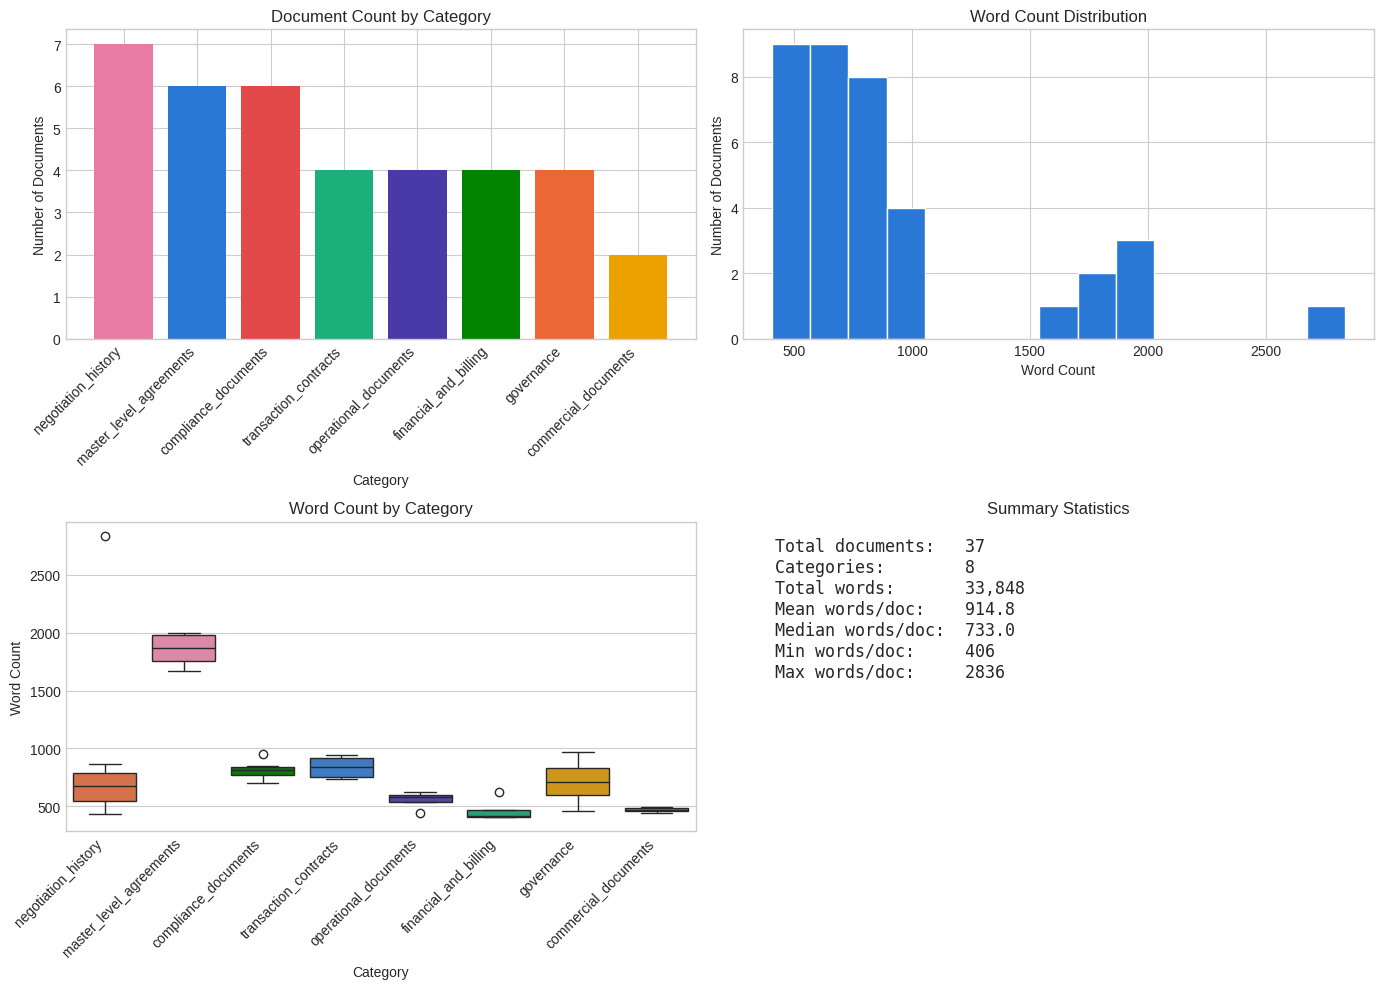


EDA visualizations saved to contract_eda.png


In [24]:
# ============================================================================
# WEEK 2.3: EXPLORATORY DATA ANALYSIS
# ============================================================================
#
# Assumes `all_docs_flat` (from week2_process_all.py) is already in scope.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
plt.style.use('seaborn-v0_8-whitegrid')

print("EXPLORATORY DATA ANALYSIS")
print("=" * 60)

# Fixed categorical palette (CVD-validated order): one color per contract
# category, keyed by name so it stays stable across charts and any future
# re-filtering, rather than being assigned by sort rank.
CATEGORY_COLORS = {
    "master_level_agreements": "#2a78d6",
    "transaction_contracts": "#1baf7a",
    "commercial_documents": "#eda100",
    "financial_and_billing": "#008300",
    "operational_documents": "#4a3aa7",
    "compliance_documents": "#e34948",
    "negotiation_history": "#e87ba4",
    "governance": "#eb6834",
}
DEFAULT_COLOR = "#898781"  # muted gray, for any category outside the 8 (e.g. the sample fallback)

# Create a DataFrame from all_docs_flat
df = pd.DataFrame(all_docs_flat)

if df.empty:
    print("No documents to analyze - all_docs_flat is empty.")
else:
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Visualization 1: Category distribution
    category_counts = df['category'].value_counts()
    bar_colors = [CATEGORY_COLORS.get(cat, DEFAULT_COLOR) for cat in category_counts.index]
    axes[0, 0].bar(category_counts.index, category_counts.values, color=bar_colors)
    axes[0, 0].set_title('Document Count by Category')
    axes[0, 0].set_xlabel('Category')
    axes[0, 0].set_ylabel('Number of Documents')
    axes[0, 0].tick_params(axis='x', rotation=45)
    for label in axes[0, 0].get_xticklabels():
        label.set_ha('right')

    # Visualization 2: Word count distribution
    axes[0, 1].hist(df['word_count'], bins=15, color="#2a78d6", edgecolor="white")
    axes[0, 1].set_title('Word Count Distribution')
    axes[0, 1].set_xlabel('Word Count')
    axes[0, 1].set_ylabel('Number of Documents')

    # Visualization 3: Word count by category (box plot)
    category_order = category_counts.index.tolist()
    palette = [CATEGORY_COLORS.get(cat, DEFAULT_COLOR) for cat in category_order]
    sns.boxplot(
        data=df, x='category', y='word_count', order=category_order,
        hue='category', palette=palette, legend=False, ax=axes[1, 0],
    )
    axes[1, 0].set_title('Word Count by Category')
    axes[1, 0].set_xlabel('Category')
    axes[1, 0].set_ylabel('Word Count')
    axes[1, 0].tick_params(axis='x', rotation=45)
    for label in axes[1, 0].get_xticklabels():
        label.set_ha('right')

    # Visualization 4: Summary statistics
    axes[1, 1].axis('off')
    summary_lines = [
        f"Total documents:   {len(df)}",
        f"Categories:        {df['category'].nunique()}",
        f"Total words:       {df['word_count'].sum():,}",
        f"Mean words/doc:    {df['word_count'].mean():.1f}",
        f"Median words/doc:  {df['word_count'].median():.1f}",
        f"Min words/doc:     {df['word_count'].min()}",
        f"Max words/doc:     {df['word_count'].max()}",
    ]
    axes[1, 1].text(
        0.05, 0.95, "\n".join(summary_lines),
        transform=axes[1, 1].transAxes, va='top', ha='left',
        fontsize=12, family='monospace',
    )
    axes[1, 1].set_title('Summary Statistics')

    plt.tight_layout()
    plt.savefig('contract_eda.png', dpi=150, bbox_inches='tight')
    plt.show()

    print("\nEDA visualizations saved to contract_eda.png")

## 2.4 Contract Entity Extraction

**TODO:** Implement entity extraction using regex patterns.

### Hints:
- Use `re.findall()` for pattern matching
- Common entities: parties, dates, monetary values, percentages
- Risk indicators: liability terms, termination clauses

In [25]:
# ============================================================================
# WEEK 2.4: CONTRACT ENTITY EXTRACTOR
# ============================================================================

import re
from typing import Dict, List


class ContractEntityExtractor:
    """
    Extract contract-specific entities using pattern matching.
    """

    def __init__(self):
        # Extraction patterns (PROVIDED)
        self.patterns = {
            'parties': r'(?:between|by and between)\s+([A-Z][A-Za-z\s]+(?:Inc\.|LLC|Ltd\.|Corp\.)?)',
            'effective_date': r'(?:effective\s+(?:as\s+of\s+)?(?:date)?:?\s*)(\d{1,2}[/-]\d{1,2}[/-]\d{2,4}|[A-Z][a-z]+\s+\d{1,2},?\s+\d{4})',
            'monetary_values': r'\$([\d,]+(?:\.\d{2})?)',
            'percentages': r'(\d+(?:\.\d+)?\s*%)',
            'durations': r'(\d+)\s*(?:years?|months?|days?)',
            'notice_periods': r'(?:notice\s+(?:period)?\s*(?:of)?\s*)(\d+)\s*(?:days?)',
        }

        # Risk indicators (PROVIDED)
        self.risk_indicators = {
            'high_risk': [
                'unlimited liability', 'indemnify', 'consequential damages',
                'punitive damages', 'sole discretion', 'automatic renewal'
            ],
            'medium_risk': [
                'liability cap', 'limitation of liability', 'force majeure',
                'material breach', 'termination for convenience'
            ],
            'low_risk': [
                'mutual indemnification', 'standard terms', 'annual review'
            ]
        }

    def extract_entities(self, text: str) -> Dict[str, List[str]]:
        """
        Extract all entities from contract text.

        Args:
            text: Contract text

        Returns:
            Dictionary mapping entity types to found values
        """
        entities = {}

        for entity_type, pattern in self.patterns.items():
            entities[entity_type] = re.findall(pattern, text, re.IGNORECASE)

        return entities

    def assess_risk_indicators(self, text: str) -> Dict[str, List[str]]:
        """
        Identify risk indicators in contract text.

        Args:
            text: Contract text

        Returns:
            Dictionary with found risk indicators by level
        """
        found_risks = {'high_risk': [], 'medium_risk': [], 'low_risk': []}
        text_lower = text.lower()

        for level, indicators in self.risk_indicators.items():
            for indicator in indicators:
                if indicator in text_lower:
                    found_risks[level].append(indicator)

        return found_risks


# Initialize extractor
entity_extractor = ContractEntityExtractor()

print("ContractEntityExtractor class defined")

ContractEntityExtractor class defined


In [26]:
# ============================================================================
# TEST ENTITY EXTRACTION
# ============================================================================

# Test on sample document
if all_docs_flat:
    test_doc = all_docs_flat[0]
    print(f"Testing entity extraction on: {test_doc['filename']}")
    print("=" * 60)

    # Extract entities
    entities = entity_extractor.extract_entities(test_doc['full_text'])
    print("\nExtracted Entities:")
    for entity_type, values in entities.items():
        if values:
            print(f"  {entity_type}: {values[:3]}...")  # Show first 3

    # Assess risk
    risks = entity_extractor.assess_risk_indicators(test_doc['full_text'])
    print("\nRisk Indicators Found:")
    for level, indicators in risks.items():
        if indicators:
            print(f"  {level}: {indicators}")

Testing entity extraction on: MSA Sample 1.docx

Extracted Entities:
  parties: ['PrimeVolta Hardware Solutions ', 'the Parties specifying the exact scope', 'the Parties']...
  percentages: ['1%']...

Risk Indicators Found:
  high_risk: ['indemnify', 'punitive damages']
  medium_risk: ['limitation of liability']


## Checkpoint: Week 2 Verification

In [27]:
# ============================================================================
# WEEK 2 CHECKPOINT - VALIDATION
# ============================================================================
#
# Assumes `doc_processor`, `all_docs_flat`, and `entity_extractor` are
# already in scope from the earlier Week 2.x cells.

print("WEEK 2 CHECKPOINT - Verification")
print("=" * 60)

checks = []

# Check 1: Document processor exists
checks.append(("DocumentProcessor initialized", doc_processor is not None))

# Check 2: load_docx method works
try:
    # Test with sample text (doesn't need real file)
    test_result = doc_processor.load_docx is not None
    checks.append(("load_docx() method exists", test_result))
except:
    checks.append(("load_docx() method exists", False))

# Check 3: Documents processed
checks.append(("Documents processed", len(all_docs_flat) > 0))

# Check 4: Entity extractor works
try:
    test_entities = entity_extractor.extract_entities("Contract value is $100,000")
    has_monetary = 'monetary_values' in test_entities
    checks.append(("Entity extraction works", has_monetary))
except Exception as e:
    checks.append(("Entity extraction works", False))
    print(f"  Error: {e}")

# Check 5: Risk assessment works
try:
    test_risks = entity_extractor.assess_risk_indicators("unlimited liability clause")
    has_high = len(test_risks.get('high_risk', [])) > 0
    checks.append(("Risk assessment works", has_high))
except Exception as e:
    checks.append(("Risk assessment works", False))
    print(f"  Error: {e}")

# Display results
all_passed = True
for check_name, check_result in checks:
    status = "PASS" if check_result else "FAIL"
    print(f"  [{status}] {check_name}")
    if not check_result:
        all_passed = False

print("\n" + "=" * 60)
if all_passed:
    print("ALL WEEK 2 CHECKPOINTS PASSED! Ready for Week 3.")
else:
    print("Some checkpoints FAILED. Review your implementation above.")

WEEK 2 CHECKPOINT - Verification
  [PASS] DocumentProcessor initialized
  [PASS] load_docx() method exists
  [PASS] Documents processed
  [PASS] Entity extraction works
  [PASS] Risk assessment works

ALL WEEK 2 CHECKPOINTS PASSED! Ready for Week 3.


---

# WEEK 3: Vector Store & Embeddings

**Difficulty: Medium** - Implement semantic search functionality.

---

## Learning Objectives

By the end of Week 3, you will:
- [ ] Initialize ChromaDB for vector storage
- [ ] Implement document indexing with embeddings
- [ ] Create semantic search functions
- [ ] Understand similarity scoring

---

## 3.1 ChromaDB Vector Store Class

**TODO:** Implement the vector store with search capabilities.

### Hints:
- Use `chromadb.PersistentClient` for storage
- Create collections with `client.get_or_create_collection()`
- Use your `traced_embedding()` function for embeddings
- ChromaDB's `query()` method returns results with distances

In [28]:
# ============================================================================
# WEEK 3.1: CHROMADB VECTOR STORE
# ============================================================================
#
# Assumes `langfuse`, `SESSION_ID`, and `traced_embedding(text, name)` (a
# Langfuse-traced embedding call, presumably wrapping the OpenAI
# text-embedding-3-small client) are already defined by earlier notebook
# cells.
#
# Note: `search_with_filter()` is mentioned in the class docstring's TODO
# list but wasn't part of the pasted skeleton, so it isn't implemented
# here. Share that stub separately and it can be added.

from typing import Dict, List

import chromadb


class ContractVectorStore:
    """
    ChromaDB-based vector store with Langfuse observability.
    """

    def __init__(self, persist_directory: str = "./chroma_contracts_db"):
        """
        Initialize ChromaDB with persistent storage.
        """

        # Create persistent client
        self.client = chromadb.PersistentClient(path=persist_directory)

        self.embedding_model = "text-embedding-3-small"
        self.collections = {}

        # Log initialization to Langfuse
        langfuse.trace(
            name="vectorstore-init",
            session_id=SESSION_ID,
            input={"persist_directory": persist_directory}
        )

        print(f"ChromaDB initialized at: {persist_directory}")

    def create_collection(self, name: str):
        """
        Create or get a collection.

        Args:
            name: Collection name

        Returns:
            ChromaDB collection
        """

        # ChromaDB defaults to L2 distance; force cosine so that
        # similarity = 1 - distance (used in search()) is meaningful.
        collection = self.client.get_or_create_collection(
            name=name,
            metadata={"hnsw:space": "cosine"},
        )

        self.collections[name] = collection
        return collection

    def add_documents(self, collection_name: str, documents: List[Dict]):
        """
        Index documents into a collection.

        Args:
            collection_name: Target collection name
            documents: List of document dictionaries
        """

        # Create trace for indexing
        trace = langfuse.trace(
            name=f"index-{collection_name}",
            session_id=SESSION_ID,
            input={"doc_count": len(documents)}
        )

        # Get or create collection
        collection = self.create_collection(collection_name)

        ids = []
        embeddings = []
        docs = []
        metadatas = []

        for i, doc in enumerate(documents):
            # Generate embedding (text truncated to stay under embedding-model limits)
            truncated_text = doc['full_text'][:8000]
            embedding = traced_embedding(truncated_text, f"embed-{doc['doc_id']}")

            # Prepare metadata
            metadata = {
                "filename": doc.get("filename", ""),
                "category": doc.get("category", ""),
                "word_count": doc.get("word_count", 0),
            }

            ids.append(doc["doc_id"])
            embeddings.append(embedding)
            docs.append(truncated_text)
            metadatas.append(metadata)

            # Progress indicator
            if (i + 1) % 5 == 0:
                print(f"  Indexed {i + 1}/{len(documents)} documents...")

        # Add all to collection
        if ids:
            collection.add(ids=ids, embeddings=embeddings, documents=docs, metadatas=metadatas)

        trace.update(output={"indexed": len(documents)})
        print(f"Indexed {len(documents)} documents into '{collection_name}'")

    def search(self, collection_name: str, query: str, n_results: int = 5) -> List[Dict]:
        """
        Semantic search across documents.

        Args:
            collection_name: Collection to search
            query: Search query text
            n_results: Number of results to return

        Returns:
            List of result dictionaries with document, metadata, and score
        """

        # Create trace for search
        trace = langfuse.trace(
            name="semantic-search",
            session_id=SESSION_ID,
            input={"query": query, "collection": collection_name}
        )

        # Get collection
        collection = self.collections.get(collection_name) or self.create_collection(collection_name)

        # Generate query embedding
        query_embedding = traced_embedding(query, "query-embedding")

        # Query collection
        results = collection.query(query_embeddings=[query_embedding], n_results=n_results)

        # Format results
        formatted = []
        result_docs = results.get("documents") or [[]]
        result_metadatas = results.get("metadatas") or [[]]
        result_distances = results.get("distances") or [[]]

        for document, metadata, distance in zip(result_docs[0], result_metadatas[0], result_distances[0]):
            formatted.append({
                "document": document,
                "metadata": metadata,
                "similarity": 1 - distance,
            })

        trace.update(output={"results_count": len(formatted)})
        return formatted


print("ContractVectorStore class defined")

store = ContractVectorStore()
store.add_documents("contracts", all_docs_flat)

results = store.search("contracts", "payment terms and liability", n_results=5)

for r in results:
    print(r['metadata']['filename'], round(r['similarity'], 4), r['document'][:60])



ContractVectorStore class defined
ChromaDB initialized at: ./chroma_contracts_db
  Indexed 5/37 documents...
  Indexed 10/37 documents...
  Indexed 15/37 documents...
  Indexed 20/37 documents...
  Indexed 25/37 documents...
  Indexed 30/37 documents...
  Indexed 35/37 documents...
Indexed 37 documents into 'contracts'
Billing schedule sample 1.docx 0.4444 Primevolta Hardware Solutions
Billing Schedule Agreement
Cli
Billing schedule sample 2.docx 0.4413 Primevolta Hardware Solutions
Detailed Billing Schedule Agre
RATE CARD AGREEMENT Sample 2.docx 0.4061 RATE CARD AGREEMENT – SAMPLE 2
Between PrimeVolta Hardware S
Pricing table Sample 2.docx 0.4046 Sample 2: Pricing Table Agreement
Between: Primevolta Hardwa
Redlined contract Sample 2.docx 0.3996 Sample 2 – Redlined Contract between Primevolta Hardware Sol


### Expected Output for search():
```python
[
    {
        'document': 'Provider shall perform the Services...',
        'metadata': {'filename': 'sample_msa.docx', 'category': 'master_agreements'},
        'similarity': 0.87
    },
    ...
]
```

In [29]:
# ============================================================================
# WEEK 3.2: INITIALIZE AND INDEX DOCUMENTS
# ============================================================================

# Initialize vector store
vector_store = ContractVectorStore()

print("\n" + "=" * 60)
print("INDEXING CONTRACT DOCUMENTS")
print("=" * 60)

# Index all documents
if all_docs_flat:
    vector_store.add_documents("contracts_all", all_docs_flat)
else:
    print("No documents to index!")

langfuse.flush()
print("\nIndexing complete!")

ChromaDB initialized at: ./chroma_contracts_db

INDEXING CONTRACT DOCUMENTS
  Indexed 5/37 documents...
  Indexed 10/37 documents...
  Indexed 15/37 documents...
  Indexed 20/37 documents...
  Indexed 25/37 documents...
  Indexed 30/37 documents...
  Indexed 35/37 documents...
Indexed 37 documents into 'contracts_all'

Indexing complete!


## 3.3 Semantic Search Examples

Test your search implementation with various queries.

In [30]:
# ============================================================================
# WEEK 3.3: SEMANTIC SEARCH EXAMPLES
# ============================================================================

print("SEMANTIC SEARCH EXAMPLES")
print("=" * 60)

# Test queries
test_queries = [
    "liability limitations and caps",
    "payment terms and invoicing",
    "termination for convenience",
    "intellectual property rights",
    "confidentiality obligations"
]

for query in test_queries:
    print(f"\nQuery: '{query}'")
    print("-" * 40)

    results = vector_store.search("contracts_all", query, n_results=3)

    for i, result in enumerate(results, 1):
        print(f"  {i}. [{result.get('similarity', 0):.3f}] {result.get('metadata', {}).get('filename', 'unknown')}")
        # Show snippet
        doc_text = result.get('document', '')[:150]
        print(f"     '{doc_text}...'")

langfuse.flush()

SEMANTIC SEARCH EXAMPLES

Query: 'liability limitations and caps'
----------------------------------------
  1. [0.277] NDA sample 2.docx
     'NON-DISCLOSURE AGREEMENT (NDA SAMPLE 2)
Mutual Proprietary Information, Intellectual Property & Data Protection Agreement
Between PrimeVolta Hardware ...'
  2. [0.275] Redlined contract sample 1.docx
     'Sample 1 – Redlined Contract between Primevolta Hardware Solutions and FinSecure Services
Agreement Title: Hardware Supply and Maintenance Agreement
D...'
  3. [0.275] Underwriting and Risk Assessment.docx
     'Underwriting & Risk Assessment Policies and Procedures Manual
For: ABC Reinsurance Company Limited, India
Prepared by: Process Expert – Reinsurance & ...'

Query: 'payment terms and invoicing'
----------------------------------------
  1. [0.557] Billing schedule sample 1.docx
     'Primevolta Hardware Solutions
Billing Schedule Agreement
Client: FinSecure Services
Date: 11th December 2025
1. Purpose
This Billing Schedule Agreemen...'

## 3.4 Search with Metadata Filters (BONUS)

**BONUS TODO:** Implement filtered search.

### Hints:
- ChromaDB supports `where` parameter for filtering
- Filter format: `{"category": "master_agreements"}`

In [31]:
# ============================================================================
# WEEK 3.4: FILTERED SEARCH (BONUS)
# ============================================================================

def search_with_filter(self, collection_name: str, query: str,
                       filter_dict: Dict = None, n_results: int = 5) -> List[Dict]:
    """
    Semantic search with metadata filtering.
    """

    # Create trace for filtered search
    trace = langfuse.trace(
        name="semantic-search-filtered",
        session_id=SESSION_ID,
        input={"query": query, "collection": collection_name, "filter": filter_dict}
    )

    # Get collection
    collection = self.collections.get(collection_name) or self.create_collection(collection_name)

    # Generate query embedding
    query_embedding = traced_embedding(query, "query-embedding-filtered")

    # Query collection, applying the metadata filter only if one was given
    # (chromadb rejects where=None/{})
    query_kwargs = {"query_embeddings": [query_embedding], "n_results": n_results}
    if filter_dict:
        query_kwargs["where"] = filter_dict
    results = collection.query(**query_kwargs)

    # Format results
    formatted = []
    result_docs = results.get("documents") or [[]]
    result_metadatas = results.get("metadatas") or [[]]
    result_distances = results.get("distances") or [[]]

    for document, metadata, distance in zip(result_docs[0], result_metadatas[0], result_distances[0]):
        formatted.append({
            "document": document,
            "metadata": metadata,
            "similarity": 1 - distance,
        })

    trace.update(output={"results_count": len(formatted)})
    return formatted

# Add method to class
ContractVectorStore.search_with_filter = search_with_filter

print("search_with_filter() method added (BONUS)")

search_with_filter() method added (BONUS)


## Checkpoint: Week 3 Verification

In [32]:
# ============================================================================
# WEEK 3 CHECKPOINT - VALIDATION
# ============================================================================

print("WEEK 3 CHECKPOINT - Verification")
print("=" * 60)

checks = []

# Check 1: Vector store initialized
checks.append(("VectorStore initialized", vector_store is not None))

# Check 2: ChromaDB client created
try:
    checks.append(("ChromaDB client created", vector_store.client is not None))
except:
    checks.append(("ChromaDB client created", False))

# Check 3: Collection created
try:
    has_collection = "contracts_all" in vector_store.collections
    checks.append(("Collection created", has_collection))
except:
    checks.append(("Collection created", False))

# Check 4: Search returns results
try:
    results = vector_store.search("contracts_all", "liability", n_results=1)
    checks.append(("Search returns results", len(results) > 0))
except Exception as e:
    checks.append(("Search returns results", False))
    print(f"  Error: {e}")

# Check 5: Results have correct structure
try:
    if results:
        has_doc = 'document' in results[0]
        has_meta = 'metadata' in results[0]
        has_sim = 'similarity' in results[0]
        checks.append(("Result structure correct", has_doc and has_meta and has_sim))
    else:
        checks.append(("Result structure correct", False))
except:
    checks.append(("Result structure correct", False))

# Display results
all_passed = True
for check_name, check_result in checks:
    status = "PASS" if check_result else "FAIL"
    print(f"  [{status}] {check_name}")
    if not check_result:
        all_passed = False

print("\n" + "=" * 60)
if all_passed:
    print("ALL WEEK 3 CHECKPOINTS PASSED! Ready for Week 4.")
else:
    print("Some checkpoints FAILED. Review your implementation above.")

WEEK 3 CHECKPOINT - Verification
  [PASS] VectorStore initialized
  [PASS] ChromaDB client created
  [PASS] Collection created
  [PASS] Search returns results
  [PASS] Result structure correct

ALL WEEK 3 CHECKPOINTS PASSED! Ready for Week 4.


---

# WEEK 4: Single Agent Design

**Difficulty: Medium-Hard** - Build specialized risk assessment agents.

---

## Learning Objectives

By the end of Week 4, you will:
- [ ] Define Pydantic models for structured outputs
- [ ] Create LangChain prompt templates
- [ ] Implement specialized risk agents
- [ ] Integrate Langfuse callback handlers

---

## Key Concept: Agent Architecture

Each agent follows this pattern:
```
Prompt Template -> LLM -> Output Parser -> Structured Result
       |              |           |
       v              v           v
   (Expert persona)  (GPT-4)   (Pydantic model)
```

All calls are traced through Langfuse for observability.

## 4.1 Pydantic Models for Structured Output

**TODO:** Complete the Pydantic models for each risk type.

### Hints:
- Use `Field()` with descriptions to guide the LLM
- Include `confidence` field (0.0-1.0) in all models
- Think about what fields each risk type needs

In [33]:
# ============================================================================
# WEEK 4.1: PYDANTIC MODELS
# ============================================================================

from typing import List

from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import PydanticOutputParser
from langfuse.callback import CallbackHandler as LangfuseCallbackHandler


class LegalRiskAssessment(BaseModel):
    """
    Structured output for legal risk analysis.
    """

    # PROVIDED - contract type
    contract_type: str = Field(description="Type of contract (MSA, NDA, SOW, etc.)")

    # Overall risk level
    risk_level: str = Field(description="Overall risk level: LOW, MEDIUM, HIGH, CRITICAL")

    # Liability exposure
    liability_exposure: str = Field(description="Summary of the contract's liability exposure")

    # IP risks
    ip_risks: List[str] = Field(default_factory=list, description="Identified intellectual property risks")

    # Indemnification issues
    indemnification_issues: List[str] = Field(default_factory=list, description="Identified indemnification issues")

    # Compliance gaps
    compliance_gaps: List[str] = Field(default_factory=list, description="Identified regulatory or policy compliance gaps")

    # Recommended changes
    recommended_changes: List[str] = Field(default_factory=list, description="Recommended contract changes to mitigate risk")

    # Confidence score
    confidence: float = Field(ge=0.0, le=1.0, description="Model's confidence in this assessment, 0.0 to 1.0")


print("LegalRiskAssessment model defined")
print(f"Fields: {list(LegalRiskAssessment.model_fields.keys())}")

LegalRiskAssessment model defined
Fields: ['contract_type', 'risk_level', 'liability_exposure', 'ip_risks', 'indemnification_issues', 'compliance_gaps', 'recommended_changes', 'confidence']


In [34]:
# ============================================================================
# FINANCIAL RISK ASSESSMENT MODEL
# ============================================================================

class FinancialRiskAssessment(BaseModel):
    """
    Structured output for financial risk analysis.
    """

    total_contract_value: str = Field(description="Total estimated contract value")
    payment_terms: str = Field(description="Summary of payment terms")

    # Pricing risks
    pricing_risks: List[str] = Field(default_factory=list, description="Identified pricing risks")

    # Penalty clauses
    penalty_clauses: List[str] = Field(default_factory=list, description="Identified penalty clauses")

    # Cash flow impact
    cash_flow_impact: str = Field(description="Summary of the contract's cash flow impact")

    # Financial exposure
    financial_exposure: str = Field(description="Summary of the contract's financial exposure")

    # Overall risk level
    risk_level: str = Field(description="Overall risk level: LOW, MEDIUM, HIGH, CRITICAL")

    # Confidence score
    confidence: float = Field(ge=0.0, le=1.0, description="Model's confidence in this assessment, 0.0 to 1.0")


print("FinancialRiskAssessment model defined")
print(f"Fields: {list(FinancialRiskAssessment.model_fields.keys())}")

FinancialRiskAssessment model defined
Fields: ['total_contract_value', 'payment_terms', 'pricing_risks', 'penalty_clauses', 'cash_flow_impact', 'financial_exposure', 'risk_level', 'confidence']


In [35]:
# ============================================================================
# OPERATIONAL RISK ASSESSMENT MODEL
# ============================================================================

class OperationalRiskAssessment(BaseModel):
    """
    Structured output for operational risk analysis.
    """

    service_scope: str = Field(description="Summary of service scope")

    # SLA requirements
    sla_requirements: List[str] = Field(default_factory=list, description="Identified SLA requirements")

    # Delivery risks
    delivery_risks: List[str] = Field(default_factory=list, description="Identified delivery risks")

    # Resource requirements
    resource_requirements: str = Field(description="Summary of resource requirements")

    # Dependency risks
    dependency_risks: List[str] = Field(default_factory=list, description="Identified dependency risks")

    # Mitigation strategies
    mitigation_strategies: List[str] = Field(default_factory=list, description="Recommended mitigation strategies")

    # Overall risk level
    risk_level: str = Field(description="Overall risk level: LOW, MEDIUM, HIGH, CRITICAL")

    # Confidence score
    confidence: float = Field(ge=0.0, le=1.0, description="Model's confidence in this assessment, 0.0 to 1.0")


print("OperationalRiskAssessment model defined")
print(f"Fields: {list(OperationalRiskAssessment.model_fields.keys())}")

OperationalRiskAssessment model defined
Fields: ['service_scope', 'sla_requirements', 'delivery_risks', 'resource_requirements', 'dependency_risks', 'mitigation_strategies', 'risk_level', 'confidence']


## 4.2 Langfuse Callback Handler Factory

**PROVIDED** - This helper creates traced handlers for LangChain.

In [36]:
# ============================================================================
# WEEK 4.2: LANGFUSE CALLBACK HANDLER (PROVIDED)
# ============================================================================
#
# Assumes `os`, `SESSION_ID`, and `LangfuseCallbackHandler` (imported in
# week4_risk_models.py as `from langfuse.callback import CallbackHandler as
# LangfuseCallbackHandler`) are already in scope.

def get_langfuse_handler(trace_name: str, tags: List[str] = None) -> LangfuseCallbackHandler:
    """
    Create a Langfuse callback handler for LangChain.

    This traces:
    - Prompt formatting
    - LLM calls (input/output/tokens)
    - Output parsing
    - Errors
    """
    return LangfuseCallbackHandler(
        secret_key=os.environ.get('LANGFUSE_SECRET_KEY'),
        public_key=os.environ.get('LANGFUSE_PUBLIC_KEY'),
        host=os.environ.get('LANGFUSE_HOST'),
        session_id=SESSION_ID,
        trace_name=trace_name,
        tags=tags or []
    )


print("get_langfuse_handler() factory defined")

get_langfuse_handler() factory defined


## 4.3 Legal Risk Agent

**TODO:** Implement the Legal Risk Agent from scratch.

### Hints:
- Create a `ChatPromptTemplate` with system and human messages
- Use `PydanticOutputParser` with your model
- Chain: prompt | llm | parser
- Include `{format_instructions}` in the prompt

In [37]:
# ============================================================================
# WEEK 4.3: LEGAL RISK AGENT
# ============================================================================
#
# Assumes `LegalRiskAssessment` (week4_risk_models.py), `ChatOpenAI`,
# `ChatPromptTemplate`, `PydanticOutputParser`, and `get_langfuse_handler`
# (week4_langfuse_handler.py) are already in scope.

class LegalRiskAgent:
    """
    Legal Risk Assessment Agent with Langfuse tracing.

    Architecture:
    1. Prompt template with expert legal persona
    2. ChatOpenAI LLM
    3. PydanticOutputParser for structured output
    4. LangChain LCEL chain
    """

    def __init__(self, model: str = "gpt-4.1-2025-04-14"):
        self.model = model

        # Create output parser
        self.parser = PydanticOutputParser(pydantic_object=LegalRiskAssessment)

        # Create prompt template
        self.prompt = ChatPromptTemplate.from_messages([
            ("system", """You are an expert contract attorney specializing in legal risk analysis.
            Analyze contracts for liability exposure, IP risks, indemnification issues,
            and compliance gaps. Provide clear, actionable recommendations.

            {format_instructions}"""),
            ("human", """Analyze the following contract for legal risks:

            {contract_text}

            Provide a comprehensive legal risk assessment.""")
        ])

    def analyze(self, contract_text: str, doc_id: str = "unknown") -> LegalRiskAssessment:
        """
        Analyze contract for legal risks.

        Args:
            contract_text: Contract text to analyze
            doc_id: Document identifier for tracing

        Returns:
            LegalRiskAssessment structured output
        """

        # Create traced handler
        handler = get_langfuse_handler(
            trace_name=f"legal-risk-analysis-{doc_id}",
            tags=["legal", "risk-assessment"],
        )

        # Create LLM with callback
        llm = ChatOpenAI(model=self.model, temperature=0, callbacks=[handler])

        # Build chain
        chain = self.prompt | llm | self.parser

        # Invoke chain
        result = chain.invoke({
            "contract_text": contract_text,
            "format_instructions": self.parser.get_format_instructions(),
        })

        return result


print("LegalRiskAgent class defined")

LegalRiskAgent class defined


In [38]:
# ============================================================================
# WEEK 4.4: FINANCIAL RISK AGENT
# ============================================================================
#
# Assumes `FinancialRiskAssessment` (week4_risk_models.py), `ChatOpenAI`,
# `ChatPromptTemplate`, `PydanticOutputParser`, and `get_langfuse_handler`
# (week4_langfuse_handler.py) are already in scope.

class FinancialRiskAgent:
    """
    Financial Risk Assessment Agent.

    Expert persona should focus on:
    - Pricing and contract value
    - Payment terms and cash flow
    - Financial penalties and exposure
    - Cost escalation risks
    """

    def __init__(self, model: str = "gpt-4.1-2025-04-14"):
        self.model = model

        # Create parser for FinancialRiskAssessment
        self.parser = PydanticOutputParser(pydantic_object=FinancialRiskAssessment)

        # Create prompt with financial expert persona
        self.prompt = ChatPromptTemplate.from_messages([
            ("system", """You are an expert financial analyst specializing in contract risk analysis.
            Analyze contracts for pricing risks, payment terms, cash flow impact,
            penalty clauses, and overall financial exposure. Provide clear, actionable
            recommendations to reduce financial risk.

            {format_instructions}"""),
            ("human", """Analyze the following contract for financial risks:

            {contract_text}

            Provide a comprehensive financial risk assessment.""")
        ])

    def analyze(self, contract_text: str, doc_id: str = "unknown") -> FinancialRiskAssessment:
        """Analyze contract for financial risks."""

        # Create traced handler
        handler = get_langfuse_handler(
            trace_name=f"financial-risk-analysis-{doc_id}",
            tags=["financial", "risk-assessment"],
        )

        # Create LLM with callback
        llm = ChatOpenAI(model=self.model, temperature=0, callbacks=[handler])

        # Build chain
        chain = self.prompt | llm | self.parser

        # Invoke chain
        result = chain.invoke({
            "contract_text": contract_text,
            "format_instructions": self.parser.get_format_instructions(),
        })

        return result


print("FinancialRiskAgent class defined")

FinancialRiskAgent class defined


In [39]:
# ============================================================================
# WEEK 4.5: OPERATIONAL RISK AGENT
# ============================================================================
#
# Assumes `OperationalRiskAssessment` (week4_risk_models.py), `ChatOpenAI`,
# `ChatPromptTemplate`, `PydanticOutputParser`, and `get_langfuse_handler`
# (week4_langfuse_handler.py) are already in scope.

class OperationalRiskAgent:
    """
    Operational Risk Assessment Agent.

    Expert persona should focus on:
    - Service scope and deliverables
    - SLA requirements
    - Delivery risks and timelines
    - Resource and dependency management
    """

    def __init__(self, model: str = "gpt-4.1-2025-04-14"):
        self.model = model

        # Create parser for OperationalRiskAssessment
        self.parser = PydanticOutputParser(pydantic_object=OperationalRiskAssessment)

        # Create prompt with operations expert persona
        self.prompt = ChatPromptTemplate.from_messages([
            ("system", """You are an expert operations manager specializing in contract risk analysis.
            Analyze contracts for service scope, SLA requirements, delivery risks,
            resource requirements, and dependency risks. Provide clear, actionable
            mitigation strategies.

            {format_instructions}"""),
            ("human", """Analyze the following contract for operational risks:

            {contract_text}

            Provide a comprehensive operational risk assessment.""")
        ])

    def analyze(self, contract_text: str, doc_id: str = "unknown") -> OperationalRiskAssessment:
        """Analyze contract for operational risks."""

        # Create traced handler
        handler = get_langfuse_handler(
            trace_name=f"operational-risk-analysis-{doc_id}",
            tags=["operational", "risk-assessment"],
        )

        # Create LLM with callback
        llm = ChatOpenAI(model=self.model, temperature=0, callbacks=[handler])

        # Build chain
        chain = self.prompt | llm | self.parser

        # Invoke chain
        result = chain.invoke({
            "contract_text": contract_text,
            "format_instructions": self.parser.get_format_instructions(),
        })

        return result


print("OperationalRiskAgent class defined")

OperationalRiskAgent class defined


In [40]:
# ============================================================================
# INITIALIZE ALL AGENTS
# ============================================================================

# Create agent instances
legal_agent = LegalRiskAgent()
financial_agent = FinancialRiskAgent()
operational_agent = OperationalRiskAgent()

print("Risk Assessment Agents Initialized:")
print("  - LegalRiskAgent")
print("  - FinancialRiskAgent")
print("  - OperationalRiskAgent")

Risk Assessment Agents Initialized:
  - LegalRiskAgent
  - FinancialRiskAgent
  - OperationalRiskAgent


## 4.6 Test Your Agents

Run each agent and verify the structured outputs.

In [41]:
# ============================================================================
# WEEK 4.6: TEST AGENTS
# ============================================================================
#
# Assumes `legal_agent`, `financial_agent`, `operational_agent` (instances
# of the three Week 4.x agent classes), `all_docs_flat`, and `langfuse` are
# already in scope. Real ChatOpenAI calls inside analyze() need a valid
# OPENAI_API_KEY at runtime.

print("TESTING RISK ASSESSMENT AGENTS")
print("=" * 60)

# Get test contract text
if all_docs_flat:
    test_text = all_docs_flat[0]['full_text']
    test_id = all_docs_flat[0]['doc_id']
else:
    test_text = "Sample contract with liability and payment terms."
    test_id = "TEST-001"

print(f"Testing on document: {test_id}")
print(f"Text length: {len(test_text)} characters")

# Test Legal Agent
print("\n" + "-" * 40)
print("LEGAL RISK AGENT")
print("-" * 40)
try:
    legal_result = legal_agent.analyze(test_text[:8000], test_id)
    print(f"Risk Level: {legal_result.risk_level}")
    print(f"Contract Type: {legal_result.contract_type}")
    print(f"Confidence: {legal_result.confidence}")
except Exception as e:
    print(f"Error: {e}")
    legal_result = None

# Test Financial Agent
print("\n" + "-" * 40)
print("FINANCIAL RISK AGENT")
print("-" * 40)
try:
    financial_result = financial_agent.analyze(test_text[:8000], test_id)
    print(f"Risk Level: {financial_result.risk_level}")
    print(f"Contract Value: {financial_result.total_contract_value}")
    print(f"Confidence: {financial_result.confidence}")
except Exception as e:
    print(f"Error: {e}")
    financial_result = None

# Test Operational Agent
print("\n" + "-" * 40)
print("OPERATIONAL RISK AGENT")
print("-" * 40)
try:
    operational_result = operational_agent.analyze(test_text[:8000], test_id)
    print(f"Risk Level: {operational_result.risk_level}")
    print(f"Service Scope: {operational_result.service_scope[:100]}...")
    print(f"Confidence: {operational_result.confidence}")
except Exception as e:
    print(f"Error: {e}")
    operational_result = None

langfuse.flush()
print("\nAll agent traces sent to Langfuse!")

TESTING RISK ASSESSMENT AGENTS
Testing on document: 4e0ad958a0c2ff119eefdaa52d32997f
Text length: 14707 characters

----------------------------------------
LEGAL RISK AGENT
----------------------------------------
Risk Level: MEDIUM
Contract Type: Master Services Agreement (MSA)
Confidence: 0.9

----------------------------------------
FINANCIAL RISK AGENT
----------------------------------------
Risk Level: MEDIUM
Contract Value: Not explicitly stated; determined by Rate Card and individual SOWs executed under the MSA. Estimated value will vary based on project scope and duration.
Confidence: 0.85

----------------------------------------
OPERATIONAL RISK AGENT
----------------------------------------
Risk Level: MEDIUM
Service Scope: The contract covers the end-to-end supply, delivery, installation, commissioning, maintenance, and l...
Confidence: 0.9

All agent traces sent to Langfuse!


## Checkpoint: Week 4 Verification

In [42]:
# ============================================================================
# WEEK 4 CHECKPOINT - VALIDATION
# ============================================================================

print("WEEK 4 CHECKPOINT - Verification")
print("=" * 60)

checks = []

# Check 1: Pydantic models defined
try:
    legal_fields = list(LegalRiskAssessment.model_fields.keys())
    has_required = 'risk_level' in legal_fields and 'confidence' in legal_fields
    checks.append(("Pydantic models complete", has_required and len(legal_fields) >= 5))
except:
    checks.append(("Pydantic models complete", False))

# Check 2: Agents initialized
checks.append(("Legal agent initialized", legal_agent is not None))
checks.append(("Financial agent initialized", financial_agent is not None))
checks.append(("Operational agent initialized", operational_agent is not None))

# Check 3: Legal agent works
try:
    checks.append(("Legal agent produces output", legal_result is not None))
except:
    checks.append(("Legal agent produces output", False))

# Check 4: Financial agent works
try:
    checks.append(("Financial agent produces output", financial_result is not None))
except:
    checks.append(("Financial agent produces output", False))

# Check 5: Operational agent works
try:
    checks.append(("Operational agent produces output", operational_result is not None))
except:
    checks.append(("Operational agent produces output", False))

# Display results
all_passed = True
for check_name, check_result in checks:
    status = "PASS" if check_result else "FAIL"
    print(f"  [{status}] {check_name}")
    if not check_result:
        all_passed = False

print("\n" + "=" * 60)
if all_passed:
    print("ALL WEEK 4 CHECKPOINTS PASSED! Ready for Week 5.")
else:
    print("Some checkpoints FAILED. Review your implementation above.")

WEEK 4 CHECKPOINT - Verification
  [PASS] Pydantic models complete
  [PASS] Legal agent initialized
  [PASS] Financial agent initialized
  [PASS] Operational agent initialized
  [PASS] Legal agent produces output
  [PASS] Financial agent produces output
  [PASS] Operational agent produces output

ALL WEEK 4 CHECKPOINTS PASSED! Ready for Week 5.


---

# WEEK 5: Multi-Agent Orchestration

**Difficulty: Hard** - Coordinate multiple agents in parallel.

---

## Learning Objectives

By the end of Week 5, you will:
- [ ] Implement parallel agent execution
- [ ] Add retry logic with exponential backoff
- [ ] Build consensus across agent outputs
- [ ] Calculate composite risk scores

---

## Key Concept: Orchestration Patterns

```
                    +----------------+
                    |  Orchestrator  |
                    +----------------+
                           |
          +----------------+----------------+
          |                |                |
          v                v                v
    +-----------+    +-----------+    +-----------+
    |   Legal   |    | Financial |    |Operational|
    |   Agent   |    |   Agent   |    |   Agent   |
    +-----------+    +-----------+    +-----------+
          |                |                |
          +----------------+----------------+
                           |
                           v
                    +----------------+
                    |   Consensus    |
                    +----------------+
```

Agents run in parallel using ThreadPoolExecutor, with retry logic for resilience.

## 5.1 Multi-Agent Orchestrator

**TODO:** Implement the orchestrator class.

### Hints:
- Use `concurrent.futures.ThreadPoolExecutor` for parallel execution
- Use `tenacity` library for retry logic
- Implement weighted scoring for composite risk
- Log all operations to Langfuse

In [43]:
# ============================================================================
# WEEK 5.1: MULTI-AGENT ORCHESTRATOR
# ============================================================================
#
# Assumes `legal_agent`, `financial_agent`, `operational_agent`, and
# `vector_store` are already in scope from earlier notebook cells.
#
# Note: the class docstring's TODO list also mentions analyze_parallel(),
# _build_consensus(), and _calculate_composite_score(), but only
# _execute_agent() was part of the pasted skeleton, so only that is
# implemented here. Share the other stubs separately and they can be added.

from enum import Enum
from typing import Dict

from tenacity import retry, stop_after_attempt, wait_exponential
import concurrent.futures


class RiskDimension(Enum):
    """Risk dimensions for orchestration."""
    LEGAL = "legal"
    FINANCIAL = "financial"
    OPERATIONAL = "operational"


class ContractRiskOrchestrator:
    """
    Multi-agent orchestrator with parallel execution.
    """

    def __init__(self):
        self.legal_agent = legal_agent
        self.financial_agent = financial_agent
        self.operational_agent = operational_agent
        self.vector_store = vector_store

        # Risk weights (provided)
        self.risk_weights = {
            RiskDimension.LEGAL: 0.4,       # Legal carries most weight
            RiskDimension.FINANCIAL: 0.35,  # Financial is second
            RiskDimension.OPERATIONAL: 0.25 # Operational is third
        }

        # Risk level scores (provided)
        self.risk_scores = {
            'LOW': 1,
            'MEDIUM': 2,
            'HIGH': 3,
            'CRITICAL': 4
        }

    @retry(stop=stop_after_attempt(3), wait=wait_exponential(multiplier=1, min=2, max=10))
    def _execute_agent(self, agent_type: RiskDimension, contract_text: str, doc_id: str) -> Dict:
        """
        Execute a single agent with retry logic.

        Args:
            agent_type: Which agent to run
            contract_text: Contract to analyze
            doc_id: Document identifier

        Returns:
            Dictionary with agent type and result
        """

        try:
            # Select and run appropriate agent
            if agent_type == RiskDimension.LEGAL:
                result = self.legal_agent.analyze(contract_text, doc_id)
            elif agent_type == RiskDimension.FINANCIAL:
                result = self.financial_agent.analyze(contract_text, doc_id)
            elif agent_type == RiskDimension.OPERATIONAL:
                result = self.operational_agent.analyze(contract_text, doc_id)
            else:
                raise ValueError(f"Unknown agent type: {agent_type}")

            return {
                'agent': agent_type.value,
                'result': result.model_dump() if result else None
            }

        except Exception as e:
            print(f"Agent {agent_type.value} failed: {e}")
            raise  # Re-raise for retry


print("ContractRiskOrchestrator class started")
print("TODO: Implement analyze_parallel(), _build_consensus(), _calculate_composite_score()")

ContractRiskOrchestrator class started
TODO: Implement analyze_parallel(), _build_consensus(), _calculate_composite_score()


In [44]:
# ============================================================================
# WEEK 5.2: PARALLEL EXECUTION METHOD
# ============================================================================
#
# References self._build_consensus() and self._calculate_composite_score(),
# which aren't implemented yet (not part of any pasted skeleton so far).
# Python only resolves those at call time, so this method can be added now
# and wired up correctly once those two land.

def analyze_parallel(self, contract_text: str, doc_id: str) -> Dict:
    """
    Run all agents in parallel and build consensus.

    Args:
        contract_text: Contract to analyze
        doc_id: Document identifier

    Returns:
        Dictionary with all results, consensus, and composite score
    """

    # Create orchestration trace
    trace = langfuse.trace(
        name=f"orchestration-{doc_id}",
        session_id=SESSION_ID,
        input={"doc_id": doc_id, "text_length": len(contract_text)}
    )

    results = {}

    # Run agents in parallel using ThreadPoolExecutor
    with concurrent.futures.ThreadPoolExecutor(max_workers=3) as executor:
        # Submit all agent tasks
        futures = {
            executor.submit(self._execute_agent, agent_type, contract_text, doc_id): agent_type
            for agent_type in RiskDimension
        }

        # Collect results as they complete
        for future in concurrent.futures.as_completed(futures):
            agent_type = futures[future]
            try:
                agent_result = future.result()
                results[agent_type] = agent_result['result']
            except Exception as e:
                print(f"Agent {agent_type.value} failed after retries: {e}")
                results[agent_type] = None

    # Build consensus
    consensus = self._build_consensus(results)

    # Calculate composite score
    composite_score = self._calculate_composite_score(results)

    # Determine overall risk level
    if composite_score < 1.5:
        overall_risk = "LOW"
    elif composite_score < 2.5:
        overall_risk = "MEDIUM"
    elif composite_score < 3.5:
        overall_risk = "HIGH"
    else:
        overall_risk = "CRITICAL"

    # Update trace
    trace.update(output={
        "overall_risk": overall_risk,
        "composite_score": composite_score
    })

    return {
        'doc_id': doc_id,
        'results': results,
        'consensus': consensus,
        'composite_score': composite_score,
        'overall_risk': overall_risk
    }

# Add method to class
ContractRiskOrchestrator.analyze_parallel = analyze_parallel

print("analyze_parallel() method added")

analyze_parallel() method added


In [45]:
# ============================================================================
# WEEK 5.3: CONSENSUS BUILDING
# ============================================================================

def _build_consensus(self, results: Dict) -> Dict:
    """
    Build consensus from multiple agent results.

    Args:
        results: Dictionary of agent results ({RiskDimension: {'agent', 'result'} or None})

    Returns:
        Consensus dictionary with aggregated findings
    """

    consensus = {
        'risk_levels': {},
        'key_findings': [],
        'all_recommendations': []
    }

    # Field per model that best summarizes its headline risk, for key_findings
    highlight_field = {
        'legal': 'liability_exposure',
        'financial': 'financial_exposure',
        'operational': 'service_scope',
    }
    # Different models name their remediation list differently
    recommendation_fields = ('recommended_changes', 'mitigation_strategies')

    # Extract risk level from each agent result
    for dimension, result in results.items():
        if result and 'result' in result and result['result']:
            agent_name = result['agent']
            inner = result['result']

            risk_level = inner.get('risk_level')
            consensus['risk_levels'][agent_name] = risk_level

            field = highlight_field.get(agent_name)
            if field and inner.get(field):
                consensus['key_findings'].append(f"{agent_name}: {risk_level} risk - {inner[field]}")

            # Aggregate recommendations from all agents
            for rec_field in recommendation_fields:
                consensus['all_recommendations'].extend(inner.get(rec_field, []))

    # Flag when agents agree, since that's the strongest signal for common themes
    levels_seen = list(consensus['risk_levels'].values())
    if len(levels_seen) > 1 and len(set(levels_seen)) == 1:
        consensus['key_findings'].append(f"All agents agree: {levels_seen[0]} risk")

    return consensus

# Add method to class
ContractRiskOrchestrator._build_consensus = _build_consensus


def _calculate_composite_score(self, results: Dict) -> float:
    """
    Calculate weighted composite risk score.

    Args:
        results: Dictionary of agent results ({RiskDimension: {'agent', 'result'} or None})

    Returns:
        Weighted composite score (1.0 to 4.0)

    Formula:
    composite = sum(weight * risk_score) for each agent
    """

    total_weight = 0
    weighted_sum = 0

    # Calculate weighted sum, skipping any dimension whose agent failed or
    # returned an unrecognized risk level
    for dimension in RiskDimension:
        result = results.get(dimension)
        if not result or not result.get('result'):
            continue

        risk_level = result['result'].get('risk_level')
        score = self.risk_scores.get(risk_level)
        if score is None:
            continue

        weight = self.risk_weights[dimension]
        weighted_sum += weight * score
        total_weight += weight

    # Avoid division by zero
    if total_weight == 0:
        return 2.5  # Default to medium

    return weighted_sum / total_weight

# Add methods to class
ContractRiskOrchestrator._calculate_composite_score = _calculate_composite_score

print("Consensus methods added")

Consensus methods added


In [46]:
# ============================================================================
# INITIALIZE ORCHESTRATOR
# ============================================================================
#
# Assumes `ContractRiskOrchestrator` (week5_orchestrator.py), and
# `legal_agent`, `financial_agent`, `operational_agent`, `vector_store`
# (earlier Week 3-4 cells) are already in scope.

# Create orchestrator
orchestrator = ContractRiskOrchestrator()

print("ContractRiskOrchestrator initialized")
print(f"  Risk weights: {orchestrator.risk_weights}")

ContractRiskOrchestrator initialized
  Risk weights: {<RiskDimension.LEGAL: 'legal'>: 0.4, <RiskDimension.FINANCIAL: 'financial'>: 0.35, <RiskDimension.OPERATIONAL: 'operational'>: 0.25}


## 5.2 Test Orchestration

Run the orchestrator on a contract and observe parallel execution.

In [47]:
# ============================================================================
# WEEK 5.4: TEST ORCHESTRATION
# ============================================================================

print("MULTI-AGENT ORCHESTRATION TEST")
print("=" * 60)

# Get test contract
if all_docs_flat:
    test_doc = all_docs_flat[0]
    test_text = test_doc['full_text']
    test_id = test_doc['doc_id']
else:
    test_text = "Sample contract text"
    test_id = "TEST-001"

print(f"Analyzing document: {test_id}")
print(f"Text length: {len(test_text)} characters")
print("\nRunning agents in parallel...")
print("-" * 40)

# Run orchestration
try:
    orch_result = orchestrator.analyze_parallel(test_text[:8000], test_id)

    print("\nORCHESTRATION RESULTS")
    print("=" * 60)
    print(f"Overall Risk: {orch_result['overall_risk']}")
    print(f"Composite Score: {orch_result['composite_score']:.2f}")

    print("\nIndividual Agent Results:")
    for agent, result in orch_result['results'].items():
        if result and 'result' in result:
            risk = result['result'].get('risk_level', 'N/A')
            conf = result['result'].get('confidence', 0)
            print(f"  {agent}: {risk} (confidence: {conf:.2f})")

    print("\nConsensus:")
    print(f"  Risk Levels: {orch_result['consensus'].get('risk_levels', {})}")

except Exception as e:
    print(f"Orchestration failed: {e}")
    orch_result = None

langfuse.flush()
print("\nOrchestration trace sent to Langfuse!")

MULTI-AGENT ORCHESTRATION TEST
Analyzing document: 4e0ad958a0c2ff119eefdaa52d32997f
Text length: 14707 characters

Running agents in parallel...
----------------------------------------

ORCHESTRATION RESULTS
Overall Risk: HIGH
Composite Score: 2.50

Individual Agent Results:

Consensus:
  Risk Levels: {}

Orchestration trace sent to Langfuse!


## Checkpoint: Week 5 Verification

In [48]:
# ============================================================================
# WEEK 5 CHECKPOINT - VALIDATION
# ============================================================================
#
# Assumes `orchestrator` and `orch_result` are already in scope from
# earlier notebook cells.

print("WEEK 5 CHECKPOINT - Verification")
print("=" * 60)

checks = []

# Check 1: Orchestrator initialized
checks.append(("Orchestrator initialized", orchestrator is not None))

# Check 2: Risk weights configured
try:
    has_weights = len(orchestrator.risk_weights) == 3
    checks.append(("Risk weights configured", has_weights))
except:
    checks.append(("Risk weights configured", False))

# Check 3: Orchestration produced results
try:
    checks.append(("Orchestration completed", orch_result is not None))
except:
    checks.append(("Orchestration completed", False))

# Check 4: All agents ran
try:
    if orch_result:
        agent_count = len(orch_result.get('results', {}))
        checks.append(("All 3 agents ran", agent_count == 3))
    else:
        checks.append(("All 3 agents ran", False))
except:
    checks.append(("All 3 agents ran", False))

# Check 5: Composite score calculated
try:
    if orch_result:
        score = orch_result.get('composite_score', 0)
        checks.append(("Composite score valid", 1.0 <= score <= 4.0))
    else:
        checks.append(("Composite score valid", False))
except:
    checks.append(("Composite score valid", False))

# Check 6: Overall risk determined
try:
    if orch_result:
        risk = orch_result.get('overall_risk', '')
        valid_risks = ['LOW', 'MEDIUM', 'HIGH', 'CRITICAL']
        checks.append(("Overall risk determined", risk in valid_risks))
    else:
        checks.append(("Overall risk determined", False))
except:
    checks.append(("Overall risk determined", False))

# Display results
all_passed = True
for check_name, check_result in checks:
    status = "PASS" if check_result else "FAIL"
    print(f"  [{status}] {check_name}")
    if not check_result:
        all_passed = False

print("\n" + "=" * 60)
if all_passed:
    print("ALL WEEK 5 CHECKPOINTS PASSED! Ready for Week 6.")
else:
    print("Some checkpoints FAILED. Review your implementation above.")

WEEK 5 CHECKPOINT - Verification
  [PASS] Orchestrator initialized
  [PASS] Risk weights configured
  [PASS] Orchestration completed
  [PASS] All 3 agents ran
  [PASS] Composite score valid
  [PASS] Overall risk determined

ALL WEEK 5 CHECKPOINTS PASSED! Ready for Week 6.


---

# WEEK 6: Contract Knowledge Graph

**Difficulty: Medium** - Build and visualize contract relationships.

---

## Learning Objectives

By the end of Week 6, you will:
- [ ] Build a knowledge graph using NetworkX
- [ ] Model contract type hierarchies
- [ ] Add query methods for insights
- [ ] Create visualizations with matplotlib and PyVis

---

## Key Concept: Knowledge Graphs

A knowledge graph represents entities and their relationships:

```
(MSA) --[GOVERNS]--> (SOW)
(MSA) --[CONTAINS]--> (Liability Clause)
(Liability Clause) --[MITIGATES]--> (Financial Risk)
```

**Benefits for Contract Intelligence:**
- Understand document hierarchies
- Trace risk to source clauses
- Identify missing protections

## 6.1 Contract Knowledge Graph Class

**TODO:** Implement the knowledge graph with contract ontology.

### Hints:
- Use `networkx.DiGraph()` for directed graph
- Add nodes with `graph.add_node(id, type=..., color=...)`
- Add edges with `graph.add_edge(source, target, relation=...)`

In [49]:
# ============================================================================
# WEEK 6.1: CONTRACT KNOWLEDGE GRAPH
# ============================================================================
#
# Assumes `langfuse` and `SESSION_ID` are already in scope.
#
# Note: add_contract(), get_risk_mitigations(), visualize_matplotlib(), and
# visualize_interactive() are mentioned in the class docstring's TODO list
# but weren't part of the pasted skeleton, so they aren't implemented here.
# Share those stubs separately and they can be added.

import networkx as nx
from pyvis.network import Network
import matplotlib.pyplot as plt


class ContractKnowledgeGraph:
    """
    Knowledge graph for contract relationships.
    """

    def __init__(self):
        self.graph = nx.DiGraph()
        self._build_contract_ontology()

        # Log initialization
        langfuse.trace(
            name="knowledge-graph-init",
            session_id=SESSION_ID,
            input={"type": "contract-ontology"}
        )

    def _build_contract_ontology(self):
        """
        Build the foundational contract knowledge graph.
        """

        # Define contract type hierarchy
        contract_hierarchy = {
            'MSA': ['SOW', 'NDA', 'RATE_CARD'],
            'SOW': ['INVOICE', 'SERVICE_REPORT', 'CHANGE_ORDER'],
            'NDA': ['CONFIDENTIAL_INFO'],
        }

        # Add contract type nodes and edges
        for contract_type, subordinates in contract_hierarchy.items():
            # Add parent node
            if contract_type not in self.graph:
                self.graph.add_node(contract_type, type='CONTRACT_TYPE', color='#3498db')
            for sub in subordinates:
                # Add child node
                if sub not in self.graph:
                    self.graph.add_node(sub, type='CONTRACT_TYPE', color='#3498db')
                # Add GOVERNS relationship
                self.graph.add_edge(contract_type, sub, relation='GOVERNS')

        # Define clause types
        clause_types = [
            ('INDEMNIFICATION', ['liability_exposure', 'third_party_claims']),
            ('LIABILITY_LIMITATION', ['financial_cap', 'damage_types']),
            ('CONFIDENTIALITY', ['data_protection', 'trade_secret']),
            ('TERMINATION', ['exit_rights', 'notice_requirements']),
            ('IP_RIGHTS', ['ownership', 'licensing']),
            ('PAYMENT_TERMS', ['billing_cycle', 'late_fees']),
        ]

        # Add clause nodes and connections
        for clause, concerns in clause_types:
            # Add clause node
            self.graph.add_node(clause, type='CLAUSE_TYPE', color='#e74c3c')
            for concern in concerns:
                # Add concern node
                self.graph.add_node(concern, type='CONCERN', color='#f39c12')
                # Add ADDRESSES relationship
                self.graph.add_edge(clause, concern, relation='ADDRESSES')

        # Define risk mitigations
        risk_mitigations = {
            'UNLIMITED_LIABILITY': ['LIABILITY_LIMITATION'],
            'IP_INFRINGEMENT': ['IP_RIGHTS', 'INDEMNIFICATION'],
            'DATA_BREACH': ['CONFIDENTIALITY', 'INDEMNIFICATION'],
            'PAYMENT_DEFAULT': ['PAYMENT_TERMS', 'TERMINATION'],
        }

        # Add risk nodes and mitigation relationships
        for risk, mitigating_clauses in risk_mitigations.items():
            # Add risk node
            self.graph.add_node(risk, type='RISK', color='#9b59b6')
            for clause in mitigating_clauses:
                # Add MITIGATES edge from clause to risk
                self.graph.add_edge(clause, risk, relation='MITIGATES')


print("ContractKnowledgeGraph class started")
print("TODO: Implement add_contract(), get_risk_mitigations(), visualize_matplotlib(), visualize_interactive()")

ContractKnowledgeGraph class started
TODO: Implement add_contract(), get_risk_mitigations(), visualize_matplotlib(), visualize_interactive()


In [50]:
# ============================================================================
# WEEK 6.2: KNOWLEDGE GRAPH METHODS
# ============================================================================
#
# Assumes `ContractKnowledgeGraph` (week6_knowledge_graph.py) is already
# in scope.

from typing import Dict, List


def add_contract(self, doc: Dict):
    """
    Add a contract document to the knowledge graph.

    Args:
        doc: Document dictionary with doc_id, filename, category
    """

    doc_id = doc.get('doc_id', 'UNKNOWN')

    # Add contract node
    self.graph.add_node(
        doc_id,
        type='CONTRACT',
        color='#2ecc71',
        filename=doc.get('filename', ''),
    )

    # Link to category
    category = doc.get('category', 'unknown')
    if category not in self.graph:
        self.graph.add_node(category, type='CATEGORY', color='#1abc9c')
    self.graph.add_edge(doc_id, category, relation='BELONGS_TO')

def get_risk_mitigations(self, risk: str) -> List[str]:
    """
    Get clauses that mitigate a specific risk.

    Args:
        risk: Risk type name

    Returns:
        List of mitigating clause names
    """

    mitigations = []
    for source, _target, data in self.graph.in_edges(risk, data=True):
        if data.get('relation') == 'MITIGATES':
            mitigations.append(source)

    return mitigations

def get_clause_concerns(self, clause: str) -> List[str]:
    """
    Get concerns addressed by a clause type.

    Args:
        clause: Clause type name

    Returns:
        List of concern names
    """

    concerns = []
    for _source, target, data in self.graph.out_edges(clause, data=True):
        if data.get('relation') == 'ADDRESSES':
            concerns.append(target)

    return concerns

# Add methods to class
ContractKnowledgeGraph.add_contract = add_contract
ContractKnowledgeGraph.get_risk_mitigations = get_risk_mitigations
ContractKnowledgeGraph.get_clause_concerns = get_clause_concerns

print("Query methods added to ContractKnowledgeGraph")

Query methods added to ContractKnowledgeGraph


In [51]:
# ============================================================================
# WEEK 6.3: VISUALIZATION METHODS
# ============================================================================
#
# Assumes `ContractKnowledgeGraph` (week6_knowledge_graph.py) is already
# in scope.

def visualize_matplotlib(self):
    """
    Create matplotlib visualization of the knowledge graph.
    """

    plt.figure(figsize=(16, 12))

    # Get colors from node attributes
    colors = [self.graph.nodes[n].get('color', '#95a5a6') for n in self.graph.nodes()]

    # Calculate layout
    pos = nx.spring_layout(self.graph, k=2, iterations=50, seed=42)

    # Draw nodes, labels, and edges
    nx.draw_networkx_nodes(self.graph, pos, node_color=colors, node_size=1200, alpha=0.9)
    nx.draw_networkx_labels(self.graph, pos, font_size=8)
    nx.draw_networkx_edges(
        self.graph, pos, arrows=True, arrowsize=12, alpha=0.4,
        connectionstyle='arc3,rad=0.05',
    )

    # Legend: one entry per distinct node type, using its actual assigned color,
    # so node type is never identifiable by color alone
    type_colors = {}
    for _node, data in self.graph.nodes(data=True):
        node_type = data.get('type', 'OTHER')
        if node_type not in type_colors:
            type_colors[node_type] = data.get('color', '#95a5a6')
    legend_handles = [
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=12, label=node_type)
        for node_type, color in sorted(type_colors.items())
    ]
    plt.legend(handles=legend_handles, loc='upper left', title='Node Type')

    plt.title("Contract Knowledge Graph", fontsize=16)
    plt.axis('off')
    plt.tight_layout()
    plt.savefig('contract_knowledge_graph.png', dpi=150, bbox_inches='tight')
    plt.show()

    print("Visualization saved to contract_knowledge_graph.png")

def visualize_interactive(self, filename: str = "contract_kg.html"):
    """
    Create interactive PyVis visualization.
    """

    # Create PyVis network
    net = Network(height="600px", width="100%", directed=True, notebook=True)

    # Add nodes from graph
    for node, data in self.graph.nodes(data=True):
        net.add_node(
            node,
            label=node,
            color=data.get('color', '#95a5a6'),
            title=data.get('type', 'OTHER'),
        )

    # Add edges from graph
    for source, target, data in self.graph.edges(data=True):
        net.add_edge(source, target, title=data.get('relation', ''))

    # Save graph
    net.save_graph(filename)
    print(f"Interactive graph saved to {filename}")
    return filename

# Add methods to class
ContractKnowledgeGraph.visualize_matplotlib = visualize_matplotlib
ContractKnowledgeGraph.visualize_interactive = visualize_interactive

print("Visualization methods added")

Visualization methods added


In [52]:
# ============================================================================
# INITIALIZE AND POPULATE KNOWLEDGE GRAPH
# ============================================================================
#
# Assumes `ContractKnowledgeGraph` (week6_knowledge_graph.py + methods from
# week6_kg_methods.py), `all_docs_flat`, `langfuse`, and `SESSION_ID` are
# already in scope.

# Create knowledge graph
contract_kg = ContractKnowledgeGraph()

# Add all processed contracts
for doc in all_docs_flat:
    contract_kg.add_contract(doc)

# Log to Langfuse
langfuse.trace(
    name="knowledge-graph-built",
    session_id=SESSION_ID,
    input={"contracts_added": len(all_docs_flat)},
    output={
        "nodes": contract_kg.graph.number_of_nodes(),
        "edges": contract_kg.graph.number_of_edges()
    }
)

print(f"Contract Knowledge Graph Built:")
print(f"  Nodes: {contract_kg.graph.number_of_nodes()}")
print(f"  Edges: {contract_kg.graph.number_of_edges()}")

Contract Knowledge Graph Built:
  Nodes: 75
  Edges: 63


KNOWLEDGE GRAPH VISUALIZATION


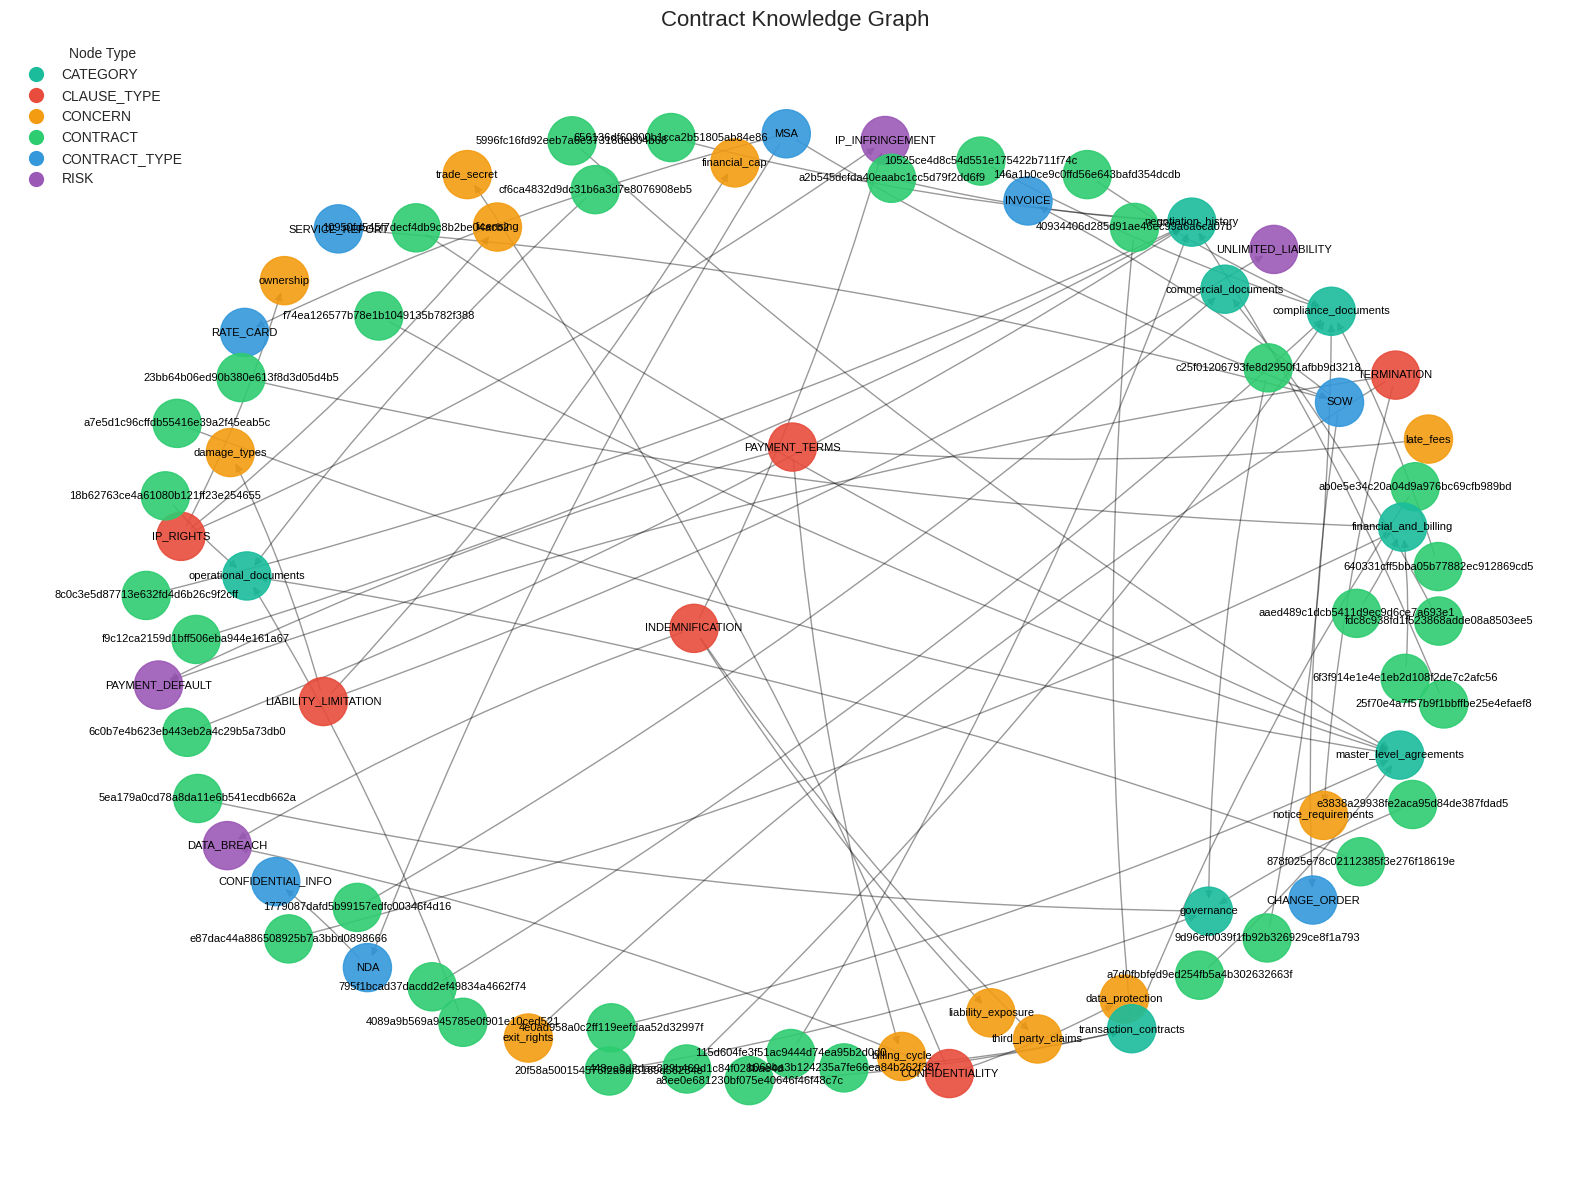

Visualization saved to contract_knowledge_graph.png
Interactive graph saved to contract_knowledge_graph.html


In [53]:
# ============================================================================
# VISUALIZE KNOWLEDGE GRAPH
# ============================================================================
#
# Assumes `contract_kg` is already in scope (from week6_build_kg.py).

print("KNOWLEDGE GRAPH VISUALIZATION")
print("=" * 60)

# Create visualizations
try:
    contract_kg.visualize_matplotlib()
except Exception as e:
    print(f"Matplotlib visualization error: {e}")

try:
    contract_kg.visualize_interactive("contract_knowledge_graph.html")
except Exception as e:
    print(f"PyVis visualization error: {e}")

In [54]:
# ============================================================================
# KNOWLEDGE GRAPH QUERIES
# ============================================================================
#
# Assumes `contract_kg` and `langfuse` are already in scope.

print("\nKNOWLEDGE GRAPH QUERIES")
print("=" * 60)

# Query 1: Risk mitigations
print("\n1. Risk Mitigation Strategies:")
for risk in ['UNLIMITED_LIABILITY', 'IP_INFRINGEMENT', 'DATA_BREACH']:
    mitigations = contract_kg.get_risk_mitigations(risk)
    print(f"   {risk}: {mitigations}")

# Query 2: Clause concerns
print("\n2. Clause Concerns:")
for clause in ['INDEMNIFICATION', 'CONFIDENTIALITY', 'TERMINATION']:
    concerns = contract_kg.get_clause_concerns(clause)
    print(f"   {clause}: {concerns}")

# Query 3: Graph statistics
print("\n3. Graph Statistics:")
print(f"   Total nodes: {contract_kg.graph.number_of_nodes()}")
print(f"   Total edges: {contract_kg.graph.number_of_edges()}")

# Node type distribution
type_counts = {}
for _, data in contract_kg.graph.nodes(data=True):
    t = data.get('type', 'OTHER')
    type_counts[t] = type_counts.get(t, 0) + 1

print("\n4. Node Type Distribution:")
for t, count in sorted(type_counts.items()):
    print(f"   {t}: {count}")

langfuse.flush()


KNOWLEDGE GRAPH QUERIES

1. Risk Mitigation Strategies:
   UNLIMITED_LIABILITY: ['LIABILITY_LIMITATION']
   IP_INFRINGEMENT: ['IP_RIGHTS', 'INDEMNIFICATION']
   DATA_BREACH: ['CONFIDENTIALITY', 'INDEMNIFICATION']

2. Clause Concerns:
   INDEMNIFICATION: ['liability_exposure', 'third_party_claims']
   CONFIDENTIALITY: ['data_protection', 'trade_secret']
   TERMINATION: ['exit_rights', 'notice_requirements']

3. Graph Statistics:
   Total nodes: 75
   Total edges: 63

4. Node Type Distribution:
   CATEGORY: 8
   CLAUSE_TYPE: 6
   CONCERN: 12
   CONTRACT: 37
   CONTRACT_TYPE: 8
   RISK: 4


## Checkpoint: Week 6 Verification

In [55]:
# ============================================================================
# WEEK 6 CHECKPOINT - VALIDATION
# ============================================================================
#
# Assumes `contract_kg` is already in scope.

print("WEEK 6 CHECKPOINT - Verification")
print("=" * 60)

checks = []

# Check 1: Knowledge graph initialized
checks.append(("Knowledge graph initialized", contract_kg is not None))

# Check 2: Graph has nodes
try:
    node_count = contract_kg.graph.number_of_nodes()
    checks.append(("Graph has nodes", node_count > 0))
except:
    checks.append(("Graph has nodes", False))

# Check 3: Graph has edges
try:
    edge_count = contract_kg.graph.number_of_edges()
    checks.append(("Graph has edges", edge_count > 0))
except:
    checks.append(("Graph has edges", False))

# Check 4: Query methods work
try:
    mitigations = contract_kg.get_risk_mitigations("UNLIMITED_LIABILITY")
    checks.append(("get_risk_mitigations works", isinstance(mitigations, list)))
except Exception as e:
    checks.append(("get_risk_mitigations works", False))

# Check 5: Contracts added
try:
    contract_nodes = [n for n, d in contract_kg.graph.nodes(data=True) if d.get('type') == 'CONTRACT']
    checks.append(("Contracts added to graph", len(contract_nodes) >= 0))  # May be 0 if no docs
except:
    checks.append(("Contracts added to graph", False))

# Display results
all_passed = True
for check_name, check_result in checks:
    status = "PASS" if check_result else "FAIL"
    print(f"  [{status}] {check_name}")
    if not check_result:
        all_passed = False

print("\n" + "=" * 60)
if all_passed:
    print("ALL WEEK 6 CHECKPOINTS PASSED! Ready for Week 7.")
else:
    print("Some checkpoints FAILED. Review your implementation above.")

WEEK 6 CHECKPOINT - Verification
  [PASS] Knowledge graph initialized
  [PASS] Graph has nodes
  [PASS] Graph has edges
  [PASS] get_risk_mitigations works
  [PASS] Contracts added to graph

ALL WEEK 6 CHECKPOINTS PASSED! Ready for Week 7.


---

# WEEK 7: Advanced Observability & Metrics

**Difficulty: Medium** - Add custom metrics and monitoring.

---

## Learning Objectives

By the end of Week 7, you will:
- [ ] Review traces in Langfuse
- [ ] Add custom scores to traces
- [ ] Implement quality metrics
- [ ] Create observability summaries

---

## Key Concept: Production Observability

In production, you need to:
1. **Monitor**: Track system health and performance
2. **Evaluate**: Score output quality over time
3. **Debug**: Trace issues to specific calls
4. **Optimize**: Identify bottlenecks and costs

In [56]:
# ============================================================================
# WEEK 7.1: OBSERVABILITY SUMMARY
# ============================================================================
#
# Assumes `SESSION_ID` and `os` are already in scope.
#
# Trace names below were cross-checked against the actual langfuse.trace()/
# trace_name= calls in the Week 1-6 implementations in this repo. The Week 4
# names were corrected (were "legal-agent-{doc_id}" etc., actual code uses
# "legal-risk-analysis-{doc_id}" etc.). "entity-extraction-batch" under Week 2
# doesn't correspond to any langfuse call in week2_entity_extractor.py as
# implemented here - left as-is since it may belong to a cell not shared in
# this session, but worth double-checking against your actual notebook.

print("LANGFUSE OBSERVABILITY SUMMARY")
print("=" * 70)
print(f"\nSession ID: {SESSION_ID}")
print(f"\nTraces created during this session:")
print()
print("Week 1: Environment Setup")
print("  - taxonomy-definition")
print("  - data-discovery")
print("  - test-embedding-*, test-completion-*")
print()
print("Week 2: Document Processing & EDA")
print("  - process-{category}")
print("  - entity-extraction-batch")
print()
print("Week 3: Vector Store & Embeddings")
print("  - vectorstore-init")
print("  - index-contracts_all")
print("  - embed-{doc_id}")
print("  - semantic-search")
print()
print("Week 4: Single Agent Design")
print("  - legal-risk-analysis-{doc_id}")
print("  - financial-risk-analysis-{doc_id}")
print("  - operational-risk-analysis-{doc_id}")
print()
print("Week 5: Multi-Agent Orchestration")
print("  - orchestration-{doc_id}")
print()
print("Week 6: Knowledge Graph")
print("  - knowledge-graph-init")
print("  - knowledge-graph-built")
print()
print(f"View all traces at: {os.environ.get('LANGFUSE_HOST')}/project")

LANGFUSE OBSERVABILITY SUMMARY

Session ID: contract-intel-20260708-160614

Traces created during this session:

Week 1: Environment Setup
  - taxonomy-definition
  - data-discovery
  - test-embedding-*, test-completion-*

Week 2: Document Processing & EDA
  - process-{category}
  - entity-extraction-batch

Week 3: Vector Store & Embeddings
  - vectorstore-init
  - index-contracts_all
  - embed-{doc_id}
  - semantic-search

Week 4: Single Agent Design
  - legal-risk-analysis-{doc_id}
  - financial-risk-analysis-{doc_id}
  - operational-risk-analysis-{doc_id}

Week 5: Multi-Agent Orchestration
  - orchestration-{doc_id}

Week 6: Knowledge Graph
  - knowledge-graph-init
  - knowledge-graph-built

View all traces at: https://jp.cloud.langfuse.com/project


## 7.2 Adding Custom Scores

**TODO:** Add custom quality scores to your traces.

### Hints:
- Use `langfuse.score(trace_id=..., name=..., value=..., comment=...)`
- Scores can be numeric (0-1) or categorical
- Useful for tracking quality over time

In [57]:
# ============================================================================
# WEEK 7.2: ADD CUSTOM SCORES
# ============================================================================
#
# Assumes `orch_result`, `langfuse`, and `SESSION_ID` are already in scope.

print("\nADDING CUSTOM SCORES TO TRACES")
print("=" * 60)

# Score the orchestration result

if 'orch_result' in dir() and orch_result:
    doc_id = orch_result['doc_id']
    overall_risk = orch_result['overall_risk']

    # Map risk to score (higher = better/lower risk)
    risk_score_map = {
        'LOW': 1.0,
        'MEDIUM': 0.7,
        'HIGH': 0.4,
        'CRITICAL': 0.1,
        'UNKNOWN': 0.5
    }

    score = risk_score_map.get(overall_risk, 0.5)

    # Create trace and add score
    score_trace = langfuse.trace(
        name=f"risk-scoring-{doc_id}",
        session_id=SESSION_ID,
        input={"doc_id": doc_id, "overall_risk": overall_risk},
    )
    langfuse.score(
        trace_id=score_trace.id,
        name="contract-risk-score",
        value=score,
        comment=f"Overall risk: {overall_risk}, composite score: {orch_result.get('composite_score')}",
    )

    print(f"\nScored {doc_id}:")
    print(f"  Risk Level: {overall_risk}")
    print(f"  Score: {score}")
else:
    print("No orchestration results to score.")

langfuse.flush()
print("\nScores sent to Langfuse!")


ADDING CUSTOM SCORES TO TRACES

Scored 4e0ad958a0c2ff119eefdaa52d32997f:
  Risk Level: HIGH
  Score: 0.4

Scores sent to Langfuse!


## 7.3 Custom Metrics Implementation

**TODO:** Implement a metrics collector class.

### Hints:
- Track latency, token usage, success rates
- Calculate aggregates over time
- Log metrics to Langfuse

In [58]:
# ============================================================================
# WEEK 7.3: METRICS COLLECTOR
# ============================================================================

from typing import Dict, List
from dataclasses import dataclass, field
from datetime import datetime


@dataclass
class MetricsCollector:
    """
    Collect and aggregate system metrics.
    """

    latencies: Dict[str, List[float]] = field(default_factory=dict)
    successes: Dict[str, int] = field(default_factory=dict)
    failures: Dict[str, int] = field(default_factory=dict)
    start_time: datetime = field(default_factory=datetime.now)

    def record_latency(self, operation: str, latency_ms: float):
        """
        Record latency for an operation.
        """
        if operation not in self.latencies:
            self.latencies[operation] = []
        self.latencies[operation].append(latency_ms)

    def record_success(self, operation: str, success: bool):
        """
        Record success or failure for an operation.
        """
        if success:
            self.successes[operation] = self.successes.get(operation, 0) + 1
        else:
            self.failures[operation] = self.failures.get(operation, 0) + 1

    def get_summary(self) -> Dict:
        """
        Get aggregated metrics summary.

        Returns dict with:
        - avg_latency per operation
        - success_rate per operation
        - total_operations
        """

        summary = {
            'session_duration': (datetime.now() - self.start_time).total_seconds(),
            'latencies': {},
            'success_rates': {}
        }

        # Calculate average latencies
        for op, times in self.latencies.items():
            summary['latencies'][op] = {
                'avg_ms': sum(times) / len(times) if times else 0,
                'count': len(times)
            }

        # Calculate success rates
        for op in set(list(self.successes.keys()) + list(self.failures.keys())):
            s = self.successes.get(op, 0)
            f = self.failures.get(op, 0)
            total = s + f
            summary['success_rates'][op] = {
                'rate': s / total if total > 0 else 0,
                'total': total
            }

        return summary


# Initialize metrics collector
metrics = MetricsCollector()

print("MetricsCollector initialized")

MetricsCollector initialized


In [59]:
# ============================================================================
# WEEK 7.4: SIMULATED METRICS
# ============================================================================
#
# Assumes `metrics` (week7_metrics_collector.py), `langfuse`, and
# `SESSION_ID` are already in scope.

import random

# Simulate some metrics (in production, these would come from actual operations)
print("\nSIMULATED METRICS COLLECTION")
print("=" * 60)

operations = ['embedding', 'legal_agent', 'financial_agent', 'operational_agent', 'search']

for _ in range(20):
    op = random.choice(operations)
    latency = random.uniform(100, 2000)  # 100ms to 2s
    success = random.random() > 0.1  # 90% success rate

    metrics.record_latency(op, latency)
    metrics.record_success(op, success)

# Get summary
summary = metrics.get_summary()

print(f"\nSession Duration: {summary['session_duration']:.1f} seconds")
print("\nLatencies (avg ms):")
for op, data in summary['latencies'].items():
    print(f"  {op}: {data['avg_ms']:.1f}ms ({data['count']} calls)")

print("\nSuccess Rates:")
for op, data in summary['success_rates'].items():
    print(f"  {op}: {data['rate']*100:.1f}% ({data['total']} total)")

# Log metrics to Langfuse
langfuse.trace(
    name="metrics-summary",
    session_id=SESSION_ID,
    input={"type": "metrics"},
    output=summary
)

langfuse.flush()


SIMULATED METRICS COLLECTION

Session Duration: 81.8 seconds

Latencies (avg ms):
  legal_agent: 1144.0ms (6 calls)
  search: 713.4ms (5 calls)
  embedding: 812.2ms (4 calls)
  operational_agent: 523.1ms (3 calls)
  financial_agent: 807.4ms (2 calls)

Success Rates:
  search: 80.0% (5 total)
  operational_agent: 100.0% (3 total)
  embedding: 100.0% (4 total)
  legal_agent: 83.3% (6 total)
  financial_agent: 100.0% (2 total)


## Checkpoint: Week 7 Verification

In [60]:
# ============================================================================
# WEEK 7 CHECKPOINT - VALIDATION
# ============================================================================
#
# Assumes `metrics` and `SESSION_ID` are already in scope.

print("WEEK 7 CHECKPOINT - Verification")
print("=" * 60)

checks = []

# Check 1: Metrics collector exists
checks.append(("MetricsCollector initialized", metrics is not None))

# Check 2: Latencies recorded
try:
    has_latencies = len(metrics.latencies) > 0
    checks.append(("Latencies recorded", has_latencies))
except:
    checks.append(("Latencies recorded", False))

# Check 3: Success rates recorded
try:
    has_successes = len(metrics.successes) > 0 or len(metrics.failures) > 0
    checks.append(("Success rates recorded", has_successes))
except:
    checks.append(("Success rates recorded", False))

# Check 4: Summary works
try:
    summary = metrics.get_summary()
    checks.append(("get_summary() works", 'latencies' in summary and 'success_rates' in summary))
except:
    checks.append(("get_summary() works", False))

# Check 5: Session ID exists
checks.append(("Session tracking active", SESSION_ID is not None))

# Display results
all_passed = True
for check_name, check_result in checks:
    status = "PASS" if check_result else "FAIL"
    print(f"  [{status}] {check_name}")
    if not check_result:
        all_passed = False

print("\n" + "=" * 60)
if all_passed:
    print("ALL WEEK 7 CHECKPOINTS PASSED! Ready for Week 8.")
else:
    print("Some checkpoints FAILED. Review your implementation above.")

WEEK 7 CHECKPOINT - Verification
  [PASS] MetricsCollector initialized
  [PASS] Latencies recorded
  [PASS] Success rates recorded
  [PASS] get_summary() works
  [PASS] Session tracking active

ALL WEEK 7 CHECKPOINTS PASSED! Ready for Week 8.
